# Graph Neural Networks from Scratch

**Self-contained Kaggle run.** Everything below executes top to bottom on a free
T4 kernel (it also runs fine on CPU -- Cora is small). No repository checkout,
no local package: the whole `gnn_lab` library is inlined into the cells in
section *"The library"*, so this file is the single source of truth for a
reproducible run.

> This notebook is **generated** by `scripts/build_kaggle_notebook.py` from the
> `gnn_lab` package. Do not edit it by hand -- edit the package and re-run the
> builder, otherwise the two copies drift apart.

| | |
|---|---|
| **Task 1** | semi-supervised node classification on Cora (2708 papers, 7 classes) |
| **Task 2** | graph-level classification on MUTAG (188 molecules) |
| **Models** | GCN, GraphSAGE, GAT, GIN -- all hand-written in plain PyTorch |
| **Verification** | every layer checked numerically against `torch_geometric` in float64 |
| **Experiments** | depth/over-smoothing, aggregator, self-loops, duplicate edges, attention |
| **Runtime** | ~10-15 min on T4, ~25 min on CPU |

## Contents
1. A graph is three tensors
2. Message passing, done by hand
3. Cora
4. Train GCN / GraphSAGE / GAT
5. Equivalence with PyTorch Geometric
6. Ablations: depth, aggregator, self-loops, duplicate edges
7. What GAT attention actually does
8. Graph-level GIN on MUTAG + the expressiveness experiment
9. Summary

---
# The library (inlined from `gnn_lab`)

The cells in this section are the package source, concatenated in dependency
order. They are generated, not written -- see the note at the top. Read them
here or in the repository; they are identical.

Each cell starts with `from __future__ import annotations` because IPython
compiles every cell independently, and the code uses PEP 604 unions
(`int | None`) in annotations.

In [24]:
# imports shared by every inlined module
from dataclasses import dataclass
from dataclasses import dataclass, field
from typing import Callable, Dict, Iterable, List, Optional, Sequence, Tuple
from typing import Callable, Dict, List, Optional
from typing import Callable, List, Optional
from typing import Dict, List, Optional
from typing import Dict, List, Optional, Sequence
from typing import Dict, List, Tuple
from typing import Iterable, Sequence
from typing import List
from typing import Optional
import copy
import math
import os
import pickle
import random
import sys
import tarfile
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import urllib.request
import zipfile

#### `ops.py` &mdash; Scatter primitives -- the engine of message passing

<details><summary>module docstring</summary>

```
Scatter primitives -- the actual mechanics underneath every GNN.
=================================================================

A graph convolution is *not* a matrix multiply over a dense adjacency matrix.
It is an **unsorted group-by**: for every target node, gather the messages
coming from its neighbours and combine them.

PyTorch spells that as ``index_add_`` / ``index_reduce_``. PyTorch Geometric
spells it as ``scatter()``. They are the same operation. This module writes it
once, from scratch, and everything else in ``gnn_lab`` builds on it.

Why this matters for learning
-----------------------------
Once you see that ``GCNConv``, ``SAGEConv``, ``GATConv`` and ``GINConv`` are
all the same three lines --

    1. build a message per edge              ``msg[e] = f(x_src[e], x_dst[e])``
    2. group messages by target node         ``out  = scatter(msg, dst, op)``
    3. update the node                       ``out  = update(out, x)``

-- then "GNN architectures" stop being a zoo of papers and become a choice of
``f``, a choice of ``op``, and a choice of ``update``.

Notation used throughout
------------------------
``edge_index`` is a ``LongTensor`` of shape ``[2, num_edges]``:

* ``edge_index[0]`` = **source** (the neighbour sending the message, often ``j``)
* ``edge_index[1]`` = **target** (the node receiving it, often ``i``)

This is the COO / PyG convention. A directed edge ``(s -> t)`` is one column.
An undirected graph is stored as both directions.
```

</details>

In [25]:
from __future__ import annotations
__all__ = [
    "scatter_add",
    "scatter_mean",
    "scatter_max",
    "scatter_sum",
    "scatter_softmax",
    "add_self_loops",
    "remove_self_loops",
    "to_undirected",
    "degree",
    "gcn_norm",
    "edge_order",
    "dense_to_edge_index",
]


# --------------------------------------------------------------------------- #
# 1. The group-by primitives
# --------------------------------------------------------------------------- #
def scatter_add(src: torch.Tensor, index: torch.LongTensor, dim_size: int, dim: int = 0) -> torch.Tensor:
    """``out[k] = sum of src[i] for all i where index[i] == k``.

    This single function is the entire engine of message passing. Every GNN
    aggregation -- sum, mean, max, attention-weighted -- is a variation on it.

    Parameters
    ----------
    src : Tensor
        One value per *edge*, shape ``[num_edges, ...]``.
    index : LongTensor
        Target group (node) id per edge, shape ``[num_edges]``.
    dim_size : int
        Number of groups = number of nodes. Needed because isolated nodes would
        otherwise silently shrink the output.

    Notes
    -----
    ``index_add_`` is atomic on CUDA, so this is safe under multi-threading and
    runs as a single fused kernel -- it is *not* a Python loop.
    """
    index = index.long()
    shape = list(src.shape)
    shape[dim] = dim_size
    out = src.new_zeros(shape)
    # No special case for an empty index: index_add_ with zero rows is a valid
    # no-op, and unlike returning a bare ``new_zeros`` it keeps ``out`` attached
    # to ``src`` in the autograd graph, so ``.backward()`` still works on a graph
    # that happens to have no edges.
    return out.index_add_(dim, index, src)


def scatter_sum(src: torch.Tensor, index: torch.LongTensor, dim_size: int, dim: int = 0) -> torch.Tensor:
    """Alias of :func:`scatter_add` (sum is the canonical name in the GIN paper)."""
    return scatter_add(src, index, dim_size, dim)


def scatter_mean(src: torch.Tensor, index: torch.LongTensor, dim_size: int, dim: int = 0) -> torch.Tensor:
    """Mean over each group. Isolated nodes get ``0`` (not ``nan``).

    Implemented as ``scatter_add(x) / count``. The count is clamped at 1 so a
    node with no incoming edges contributes a zero vector rather than NaN --
    NaNs here are the single most common source of "loss went to nan" bugs in
    hand-written GNNs.
    """
    summed = scatter_add(src, index, dim_size, dim)

    # `ones` has the same trailing shape as `src` but with every feature dim
    # collapsed to 1, so `count` broadcasts against `summed` for free.
    ones = src.new_ones((index.numel(),) + (1,) * max(src.dim() - 1, 0))
    count = scatter_add(ones, index.long(), dim_size, dim).clamp_(min=1.0)

    return summed / count


def scatter_max(src: torch.Tensor, index: torch.LongTensor, dim_size: int, dim: int = 0) -> torch.Tensor:
    """Max over each group. Isolated nodes get ``0``.

    Uses ``index_reduce_(..., 'amax')`` which is the fused CUDA group-max.
    """
    index = index.long()
    shape = list(src.shape)
    shape[dim] = dim_size

    if index.numel() == 0:
        return src.new_zeros(shape)

    out = src.new_full(shape, float("-inf"))
    out = out.index_reduce_(dim, index, src, "amax", include_self=True)
    # -inf means "no edge pointed here"; replace with 0 so downstream math is finite
    return out.masked_fill(torch.isinf(out), 0.0)


# --------------------------------------------------------------------------- #
# 2. Softmax over a group -- what makes attention an attention
# --------------------------------------------------------------------------- #
def scatter_softmax(src: torch.Tensor, index: torch.LongTensor, dim_size: int, dim: int = 0) -> torch.Tensor:
    """Softmax normalised *within each group* of ``index``.

    This is the step that turns GAT's raw scores into an attention distribution:
    every node's incoming edge weights sum to 1.

    Numerical stability
    -------------------
    We subtract the per-group max before exponentiating, exactly like the
    textbook softmax trick. The max is ``.detach()``-ed on purpose. That is
    **mathematically exact**, not an approximation: softmax is invariant to a
    constant shift of its inputs, so the shift contributes zero to the
    gradient. Detaching also sidesteps any question of whether the fused
    group-max kernel exposes a gradient.
    """
    index = index.long()

    # Every tensor here keeps `src`'s trailing shape, so a plain index_select on
    # the grouping dim is all that is needed -- no reshaping. That is what lets
    # this work unchanged for a [E] score vector *and* a [E, heads] matrix.
    group_max = scatter_max(src.detach(), index, dim_size, dim)          # [dim_size, ...]
    out = (src - group_max.index_select(dim, index)).exp()               # [E, ...]

    denom = scatter_add(out, index, dim_size, dim) + 1e-16               # [dim_size, ...]
    return out / denom.index_select(dim, index)                          # [E, ...]


# --------------------------------------------------------------------------- #
# 3. Edge-index surgery
# --------------------------------------------------------------------------- #
def add_self_loops(edge_index: torch.LongTensor, num_nodes: int) -> torch.LongTensor:
    """Append ``(i, i)`` for every node.

    GCN, GAT and GIN all do this. It is what lets a node keep its *own*
    representation in the update -- without it, a node never sees itself and
    information can only reach it through neighbours.
    """
    loop = torch.arange(num_nodes, dtype=torch.long, device=edge_index.device)
    loop = loop.unsqueeze(0).repeat(2, 1)
    return torch.cat([edge_index, loop], dim=1)


def remove_self_loops(edge_index: torch.LongTensor) -> torch.LongTensor:
    """Drop ``(i, i)`` edges."""
    mask = edge_index[0] != edge_index[1]
    return edge_index[:, mask]


def to_undirected(edge_index: torch.LongTensor, num_nodes: int) -> torch.LongTensor:
    """Symmetrise an edge list and de-duplicate it.

    Cora's citation file is directed ("paper A cites paper B") but citation
    *similarity* is symmetric, so every GNN paper on Cora symmetrises first.
    Forgetting this step is a classic silent bug: you get a plausible-looking
    accuracy that is a few points below the published number.
    """
    row, col = edge_index[0], edge_index[1]
    both = torch.cat([torch.stack([row, col]), torch.stack([col, row])], dim=1)
    # encode (u, v) as a single int64 so `unique` de-duplicates pairs
    flat = both[0] * num_nodes + both[1]
    uniq = torch.unique(flat)
    return torch.stack([uniq // num_nodes, uniq % num_nodes], dim=0)


def degree(index: torch.LongTensor, num_nodes: int, dtype=None) -> torch.Tensor:
    """Node degree = count of edges in ``index``. Returns a dense ``[num_nodes]`` vector."""
    dtype = dtype or torch.float
    return scatter_add(torch.ones(index.numel(), dtype=dtype, device=index.device), index, num_nodes)


# --------------------------------------------------------------------------- #
# 4. The GCN normalisation coefficients
# --------------------------------------------------------------------------- #
def gcn_norm(edge_index: torch.LongTensor, num_nodes: int, add_loops: bool = True,
             edge_weight: torch.Tensor | None = None,
             dtype: torch.dtype | None = None) -> tuple[torch.LongTensor, torch.Tensor]:
    """Return ``(edge_index_with_self_loops, per-edge coefficient)``.

    Computes the coefficients of

        \\hat{A} = \\tilde{D}^{-1/2} (A + I) \\tilde{D}^{-1/2}

    where ``\\tilde{D}`` is the degree matrix of ``A + I``. Concretely, edge
    ``(s -> t)`` gets weight ``1 / sqrt(deg_t * deg_s)`` *after* self-loops are
    added, so a node's own degree includes the ``+1``.

    ``dtype`` is the dtype the coefficients are computed in. It matters: if you
    compute them in float32 and cast to float64 afterwards, every coefficient
    already carries ~1e-8 of rounding error, and a float64 equivalence check
    against PyG can never get below that. The layers pass ``x.dtype`` here.

    Intuition
    ---------
    Plain averaging (``1/deg``) makes a high-degree neighbour and a low-degree
    neighbour contribute equally, which lets hub nodes dominate after several
    layers. The symmetric ``D^-1/2 A D^-1/2`` splits the discount between the
    two endpoints, which is the same normalisation a random walk with restart
    uses and is why GCN trains stably.
    """
    if dtype is None:
        dtype = edge_weight.dtype if edge_weight is not None else torch.float
    device = edge_index.device

    w = (torch.ones(edge_index.size(1), dtype=dtype, device=device)
         if edge_weight is None else edge_weight.to(dtype))

    if add_loops:
        edge_index = add_self_loops(edge_index, num_nodes)
        # the new (i, i) edges each get weight 1, so ``w`` must grow with the edge list
        w = torch.cat([w, torch.ones(num_nodes, dtype=dtype, device=device)])

    row, col = edge_index[0], edge_index[1]
    deg = scatter_add(w, col, num_nodes)                 # in-degree including self-loop
    deg_inv_sqrt = deg.pow(-0.5)
    deg_inv_sqrt.masked_fill_(torch.isinf(deg_inv_sqrt), 0.0)

    w = deg_inv_sqrt.index_select(0, row) * w * deg_inv_sqrt.index_select(0, col)
    return edge_index, w


def edge_order(edge_index: torch.LongTensor, num_nodes: int) -> torch.LongTensor:
    """Permutation that sorts edges by ``(dst, src)`` -- i.e. by column, then row.

    This is what ``torch.lexsort((src, dst))`` would do if PyTorch had one (NumPy
    does; PyTorch does not). Encoding the pair as a single int64 ``dst * N + src``
    and doing an ordinary sort is the same thing. It is also the ordering PyG
    produces from ``coalesce(..., sort_by_row=False)``, which is why the Cora
    loader and the equivalence checks need it.
    """
    key = edge_index[1] * num_nodes + edge_index[0]
    return torch.argsort(key, stable=True)


# --------------------------------------------------------------------------- #
# 5. Convenience conversions
# --------------------------------------------------------------------------- #
def dense_to_edge_index(adj: torch.Tensor) -> torch.LongTensor:
    """``[N, N]`` dense adjacency -> ``[2, E]`` COO edge index (nonzero positions)."""
    return adj.nonzero(as_tuple=False).t().contiguous()

#### `utils.py` &mdash; Seeding and device helpers

<details><summary>module docstring</summary>

```
Reproducibility and device helpers.

Seeding a GNN is slightly more involved than seeding an MLP: dropout on
attention coefficients, the random split in :func:`gnn_lab.data.cora.load_cora_linqs`,
and CUDA's non-deterministic scatter kernels all contribute. ``set_seed`` covers
the first two; for bitwise-reproducible scatter reductions you additionally need
``torch.use_deterministic_algorithms(True)``, which is slower and is therefore
left opt-in.
```

</details>

In [26]:
from __future__ import annotations
__all__ = ["set_seed", "get_device", "count_parameters", "Timer", "early_stopping"]


def set_seed(seed: int = 42, deterministic_cuda: bool = False) -> None:
    """Seed python, numpy (if present) and torch, CPU and CUDA."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import numpy as np
        np.random.seed(seed)
    except ImportError:
        pass
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if deterministic_cuda:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"


def get_device(prefer: str = "auto") -> torch.device:
    """Pick a device. ``prefer`` in {"auto", "cpu", "cuda"}."""
    if prefer == "cpu":
        return torch.device("cpu")
    if prefer == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError("CUDA requested but torch.cuda.is_available() is False")
        return torch.device("cuda")
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def count_parameters(model: torch.nn.Module, trainable_only: bool = True) -> int:
    return sum(p.numel() for p in model.parameters()
               if (p.requires_grad or not trainable_only))


class Timer:
    """Context manager + attribute for elapsed wall-clock seconds."""

    def __init__(self):
        self.elapsed = 0.0

    def __enter__(self):
        import time
        self._t = time.perf_counter()
        return self

    def __exit__(self, *exc):
        import time
        self.elapsed = time.perf_counter() - self._t
        return False


def early_stopping(patience: int = 50, mode: str = "max"):
    """Return ``(should_stop, best)`` updater for a monitored metric.

    Used by the graph-level trainer, where 188 MUTAG graphs overfit in a handful
    of epochs. Node classification on Cora is instead run for a fixed number of
    epochs, matching the published protocol -- so the two trainers differ
    deliberately.
    """
    best = -float("inf") if mode == "max" else float("inf")
    bad = 0

    def step(value: float):
        nonlocal best, bad
        improved = value > best if mode == "max" else value < best
        if improved:
            best, bad = value, 0
        else:
            bad += 1
        return bad >= patience, best

    return step

#### `metrics.py` &mdash; Metrics, including the over-smoothing diagnostics

<details><summary>module docstring</summary>

```
Metrics -- and why accuracy alone is the wrong headline number here.

Neither dataset in this repo is balanced:

* **Cora** class sizes range from 180 (Rule_Learning) to 818 (Neural_Networks).
  A model that always predicts Neural_Networks scores 30% -- low, but not
  zero, and a GNN that collapses to the majority class looks "80% accurate"
  only because it also happens to be right about the big classes.
* **MUTAG** is 63 vs 125. **Majority-class baseline is 66.5%, not 50%.** A GIN
  reporting 65% accuracy on MUTAG is worse than a constant.

So every table in this repo reports macro-F1 and the majority baseline next to
accuracy. Macro-F1 averages the per-class F1 *unweighted*, which is what you
want when you care about the rare classes too.
```

</details>

In [27]:
from __future__ import annotations
__all__ = ["accuracy", "macro_f1", "per_class_report", "confusion_matrix",
           "dirichlet_energy", "mean_pairwise_cosine", "majority_baseline"]


def accuracy(pred: torch.Tensor, target: torch.Tensor) -> float:
    return float((pred == target).float().mean().item()) if target.numel() else 0.0


def majority_baseline(target: torch.Tensor, num_classes: int) -> float:
    """Accuracy of a constant predictor. The number your model has to beat."""
    counts = torch.bincount(target, minlength=num_classes)
    return float(counts.max().item()) / float(max(target.numel(), 1))


def confusion_matrix(pred: torch.Tensor, target: torch.Tensor, num_classes: int) -> torch.Tensor:
    """``[num_classes, num_classes]`` where entry ``[t, p]`` counts true ``t`` predicted ``p``."""
    # Allocate it FLAT: (true, pred) is encoded as the single index ``true * C + pred``,
    # so a 1-D accumulator is what ``index_add_`` along dim 0 expects. Reshape at the end.
    cm = torch.zeros(num_classes * num_classes, dtype=torch.long, device=pred.device)
    cm.index_add_(0, (target * num_classes + pred).long(), torch.ones_like(target, dtype=torch.long))
    return cm.view(num_classes, num_classes)


def macro_f1(pred: torch.Tensor, target: torch.Tensor, num_classes: int) -> float:
    """Unweighted mean of per-class F1. Classes absent from ``target`` are skipped."""
    cm = confusion_matrix(pred, target, num_classes).float()
    tp = cm.diagonal()
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp

    prec = tp / (tp + fp).clamp(min=1e-12)
    rec = tp / (tp + fn).clamp(min=1e-12)
    f1 = 2 * prec * rec / (prec + rec).clamp(min=1e-12)

    support = cm.sum(dim=1)
    present = support > 0
    return float(f1[present].mean().item()) if present.any() else 0.0


def per_class_report(pred: torch.Tensor, target: torch.Tensor, num_classes: int,
                     class_names: Optional[List[str]] = None) -> Dict[str, List]:
    """Per-class precision / recall / F1 / support, as plain python lists."""
    cm = confusion_matrix(pred, target, num_classes).float()
    tp = cm.diagonal()
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp
    prec = (tp / (tp + fp).clamp(min=1e-12)).tolist()
    rec = (tp / (tp + fn).clamp(min=1e-12)).tolist()
    f1 = [2 * p * r / (p + r) if (p + r) > 0 else 0.0 for p, r in zip(prec, rec)]
    support = cm.sum(dim=1).long().tolist()
    names = class_names or [f"class_{i}" for i in range(num_classes)]
    return {"name": names, "precision": prec, "recall": rec, "f1": f1, "support": support}


# --------------------------------------------------------------------------- #
# Over-smoothing diagnostics
# --------------------------------------------------------------------------- #
def mean_pairwise_cosine(h: torch.Tensor) -> float:
    """Average cosine similarity between all pairs of node embeddings.

    Rises toward 1.0 as layers stack: that *is* over-smoothing, stated as a
    single number. On Cora a 2-layer GCN sits around 0.5-0.7 and an 8-layer one
    approaches 1.0, at which point every node has the same representation and
    no classifier can separate them.
    """
    with torch.no_grad():
        hn = torch.nn.functional.normalize(h, dim=-1)
        sim = hn @ hn.t()
        n = sim.size(0)
        if n < 2:
            return 1.0
        off_diag = (sim.sum() - sim.diagonal().sum()) / (n * n - n)
        return float(off_diag.item())


def dirichlet_energy(h: torch.Tensor, edge_index: torch.LongTensor,
                     num_nodes: Optional[int] = None) -> float:
    """Graph Dirichlet energy: ``sum_{(i,j) in E} ||h_i - h_j||^2``.

    The standard quantitative measure of over-smoothing. Message passing is
    literally a diffusion process, and diffusion monotonically *decreases* this
    energy -- neighbouring nodes are pulled together every layer. When it
    approaches 0 the features carry no class information left.

    Normalised by the number of edges so it is comparable across depths.
    """
    with torch.no_grad():
        num_nodes = num_nodes if num_nodes is not None else h.size(0)
        if edge_index.numel() == 0:
            return 0.0
        src, dst = edge_index[0], edge_index[1]
        diff = h.index_select(0, src) - h.index_select(0, dst)
        return float(diff.pow(2).sum().item() / edge_index.size(1))

#### `layers/gcn.py` &mdash; GCN layer

<details><summary>module docstring</summary>

```
GCN layer -- Kipf & Welling, "Semi-Supervised Classification with Graph
Convolutional Networks" (ICLR 2017).

The layer in one line of math
-----------------------------
.. math::

    X' = \hat{D}^{-1/2}(A + I)\hat{D}^{-1/2}\, X\, W

Read it right-to-left and it is exactly three steps:

1. ``X W``            -- a linear map, identical to a dense layer.
2. ``(A + I)``        -- add self-loops so a node keeps its own signal.
3. ``D^-1/2 ... D^-1/2`` -- weighted *mean* over the neighbourhood.

Step 3 is the only part that is graph-shaped, and it is a
:func:`~gnn_lab.ops.scatter_add`. That is the whole trick.

Index convention (this is where hand-written GNNs break)
--------------------------------------------------------
``edge_index[0]`` = **src**, the neighbour *sending* the message.
``edge_index[1]`` = **dst**, the node *receiving* it.

So a message pass is: gather from ``src``, scatter into ``dst``.

    msg[e] = x[ src[e] ] * norm[e]        # gather from the sender
    out[ dst[e] ] += msg[e]               # accumulate on the receiver

Swap those two and the code still runs, still trains, and still gives you a
plausible-looking accuracy -- just a wrong one. Keep ``src``/``dst`` named
explicitly rather than ``row``/``col``.

Parameter naming
----------------
The names ``lin`` and ``bias`` deliberately match
``torch_geometric.nn.GCNConv`` so that ``load_state_dict`` can copy weights
straight across. That is what makes the numerical equivalence test in
``gnn_lab/equivalence.py`` a one-liner instead of a fragile mapping.
```

</details>

In [28]:
from __future__ import annotations
__all__ = ["GCNConvScratch", "GCNScratch"]


class GCNConvScratch(nn.Module):
    """One graph-convolution layer, written with nothing but ``index_add_``.

    Parameters
    ----------
    in_channels, out_channels : int
        Feature dimensions.
    bias : bool
        Add a learned per-output-channel bias after propagation (default True).
    add_self_loops : bool
        Append ``(i, i)`` edges (default True). Turn this off in an ablation to
        see how much of GCN's performance is just "keep my own features".
    normalize : bool
        Apply the symmetric ``D^-1/2`` scaling (default True). Turning it off
        gives raw *sum* aggregation, which usually diverges -- a good demo of
        why the normalisation exists.
    cached_norm : bool
        Cache ``(edge_index, norm)`` for a fixed graph. Cora is trained
        full-batch on one graph, so recomputing degrees every epoch is pure
        waste. Must be left False if the graph changes between calls.
    """

    def __init__(self, in_channels: int, out_channels: int, bias: bool = True,
                 add_self_loops: bool = True, normalize: bool = True,
                 cached_norm: bool = False):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.add_self_loops_flag = add_self_loops
        self.normalize = normalize
        self.cached_norm = cached_norm
        self._cache = None

        # bias=False here; the bias is added after propagation (matches PyG)
        self.lin = nn.Linear(in_channels, out_channels, bias=False)
        if bias:
            self.bias = nn.Parameter(torch.empty(out_channels))
        else:
            self.register_parameter("bias", None)
        self.reset_parameters()

    def reset_parameters(self) -> None:
        self.lin.reset_parameters()
        self._cache = None
        if self.bias is not None:
            nn.init.zeros_(self.bias)

    def clear_cache(self) -> None:
        self._cache = None

    def _prepare(self, edge_index: torch.LongTensor, num_nodes: int, x: torch.Tensor):
        """Build (edge_index_with_loops, per_edge_coefficient), optionally cached."""
        if self.cached_norm and self._cache is not None:
            return self._cache

        if self.normalize:
            ei, norm = gcn_norm(edge_index, num_nodes, add_loops=self.add_self_loops_flag,
                                dtype=x.dtype)
        else:
            ei = add_self_loops(edge_index, num_nodes) if self.add_self_loops_flag else edge_index
            norm = torch.ones(ei.size(1), device=x.device, dtype=x.dtype)

        norm = norm.to(x.dtype)
        if self.cached_norm:
            self._cache = (ei, norm)
        return ei, norm

    # -- the three-step message pass -------------------------------------- #
    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor,
                num_nodes: int | None = None) -> torch.Tensor:
        num_nodes = num_nodes if num_nodes is not None else x.size(0)

        ei, norm = self._prepare(edge_index, num_nodes, x)
        src, dst = ei[0], ei[1]

        # ---- step 1: linear map (identical to a dense layer) -------------
        x = self.lin(x)

        # ---- step 2: MESSAGE -- gather from the sender, scale -------------
        msg = x.index_select(0, src) * norm.unsqueeze(-1)

        # ---- step 3: AGGREGATE -- unsorted group-by onto the receiver ----
        out = scatter_add(msg, dst, num_nodes)

        # ---- UPDATE: add the bias ---------------------------------------
        if self.bias is not None:
            out = out + self.bias
        return out

    def extra_repr(self) -> str:
        return (f"in={self.in_channels}, out={self.out_channels}, "
                f"normalize={self.normalize}, self_loops={self.add_self_loops_flag}")


class GCNScratch(nn.Module):
    """A complete GCN classifier: stack of :class:`GCNConvScratch`.

    This is the model Kipf & Welling used to get 81.5% on Cora, and two layers
    is still the right answer -- see the over-smoothing notebook for why more
    layers actively hurt.
    """

    def __init__(self, num_features: int, hidden_channels: int, num_classes: int,
                 num_layers: int = 2, dropout: float = 0.5, **conv_kwargs):
        super().__init__()
        self.dropout = dropout
        self.convs = nn.ModuleList()

        dims = [num_features] + [hidden_channels] * (num_layers - 1) + [num_classes]
        for i in range(num_layers):
            self.convs.append(GCNConvScratch(dims[i], dims[i + 1], **conv_kwargs))

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor) -> torch.Tensor:
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:      # no activation on the output layer
                x = F.relu(x)
                x = F.dropout(x, p=self.dropout, training=self.training)
        return x

    def embeddings(self, x, edge_index, upto: int | None = None) -> torch.Tensor:
        """Return intermediate node embeddings -- used for t-SNE and over-smoothing plots.

        ``upto=k`` stops after layer ``k`` (1-indexed), so you can compare the
        geometry of layer-1 vs layer-8 representations of the same trained net.
        """
        n = len(self.convs) if upto is None else upto
        for i, conv in enumerate(self.convs[:n]):
            x = conv(x, edge_index)
            if i < n - 1:
                x = F.relu(x)
        return x

#### `layers/sage.py` &mdash; GraphSAGE layer

<details><summary>module docstring</summary>

```
GraphSAGE layer -- Hamilton, Ying & Leskovec, "Inductive Representation
Learning on Large Graphs" (NeurIPS 2017).

What SAGE teaches you that GCN does not
---------------------------------------
GCN folds the node's own features into the average via a self-loop and one
shared weight matrix. SAGE **separates the two roles**:

.. math::

    h_i' = W_{\text{self}}\, h_i \;+\; W_{\text{neigh}}\,
           \text{AGG}\big(\{h_j : j \in N(i)\}\big)

Two independent projections, and an explicit choice of aggregator. That small
change is the source of both of SAGE's big ideas:

* **Inductive use.** Because aggregation is over whatever neighbours happen to
  be present, a node unseen at training time can still be embedded by running
  the same forward pass on its own neighbourhood. GCN's fixed
  ``D^-1/2(A+I)D^-1/2`` is tied to one specific graph.
* **Sampling.** Neighbour *sets* can be subsampled, so cost per node is bounded
  and no longer scales with degree -- which is what makes billion-edge graphs
  trainable.

The aggregator is a hyper-parameter here, which makes SAGE the best place to
feel the message-passing abstraction: same layer, swap ``mean`` for ``max``,
watch what happens.

Parameter naming matches ``torch_geometric.nn.SAGEConv`` (``lin_l`` for the
neighbour branch, ``lin_r`` for the root/self branch) so weights copy across
directly for the equivalence test.
```

</details>

In [29]:
from __future__ import annotations
__all__ = ["SAGEConvScratch", "GraphSAGEScratch", "AGGREGATORS"]

AGGREGATORS = ("mean", "max", "sum")


def _aggregate(msg: torch.Tensor, dst: torch.LongTensor, num_nodes: int, how: str) -> torch.Tensor:
    """The single line that differs between SAGE variants."""
    if how == "mean":
        return scatter_mean(msg, dst, num_nodes)
    if how == "sum":
        return scatter_add(msg, dst, num_nodes)
    if how == "max":
        return scatter_max(msg, dst, num_nodes)
    raise ValueError(f"unknown aggregator {how!r}; choose from {AGGREGATORS}")


class SAGEConvScratch(nn.Module):
    """One GraphSAGE layer.

    Parameters
    ----------
    aggr : {"mean", "max", "sum"}
        Neighbourhood combiner. ``mean`` is the paper's default and the
        strongest baseline; ``max`` sharpens on distinctive neighbours;
        ``sum`` is degree-sensitive (a hub neighbour dominates).
    root_weight : bool
        Include the ``W_self h_i`` term. Setting it False gives a *pure*
        neighbourhood model -- useful in an ablation to show how much of the
        accuracy is coming from a node's own features vs its context.
    normalize : bool
        L2-normalise the output. PyG's default is False; the original SAGE paper
        normalises between layers. Left as a switch so you can test both.

    Notes
    -----
    No self-loops are added here on purpose. ``lin_r`` already handles the node
    itself, and adding a self-loop *and* a root weight would double-count it --
    a subtle bug that silently changes what "mean" means.
    """

    def __init__(self, in_channels: int, out_channels: int, aggr: str = "mean",
                 root_weight: bool = True, normalize: bool = False, bias: bool = True):
        super().__init__()
        if aggr not in AGGREGATORS:
            raise ValueError(f"aggr must be one of {AGGREGATORS}, got {aggr!r}")
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.aggr = aggr
        self.root_weight = root_weight
        self.normalize = normalize

        self.lin_l = nn.Linear(in_channels, out_channels, bias=bias)   # neighbour branch
        if root_weight:
            self.lin_r = nn.Linear(in_channels, out_channels, bias=False)  # self branch
        else:
            self.lin_r = None
        self.reset_parameters()

    def reset_parameters(self) -> None:
        self.lin_l.reset_parameters()
        if self.lin_r is not None:
            self.lin_r.reset_parameters()

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor,
                num_nodes: int | None = None) -> torch.Tensor:
        num_nodes = num_nodes if num_nodes is not None else x.size(0)
        src, dst = edge_index[0], edge_index[1]

        # MESSAGE: SAGE's message is just the neighbour's own features.
        # All the modelling happens in the aggregator and the two projections.
        msg = x.index_select(0, src)

        # AGGREGATE over the receiver's neighbourhood.
        agg = _aggregate(msg, dst, num_nodes, self.aggr)

        # UPDATE: two independent linear branches, summed.
        out = self.lin_l(agg)
        if self.root_weight:
            out = out + self.lin_r(x)

        if self.normalize:
            out = F.normalize(out, p=2.0, dim=-1)
        return out

    def extra_repr(self) -> str:
        return (f"in={self.in_channels}, out={self.out_channels}, aggr={self.aggr}, "
                f"root_weight={self.root_weight}, normalize={self.normalize}")


class GraphSAGEScratch(nn.Module):
    """Stacked GraphSAGE classifier with ReLU + dropout between layers."""

    def __init__(self, num_features: int, hidden_channels: int, num_classes: int,
                 num_layers: int = 2, dropout: float = 0.5, aggr: str = "mean",
                 normalize: bool = False, root_weight: bool = True):
        super().__init__()
        self.dropout = dropout
        self.convs = nn.ModuleList()

        dims = [num_features] + [hidden_channels] * (num_layers - 1) + [num_classes]
        for i in range(num_layers):
            self.convs.append(SAGEConvScratch(
                dims[i], dims[i + 1], aggr=aggr,
                root_weight=root_weight, normalize=normalize))

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor) -> torch.Tensor:
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
                x = F.dropout(x, p=self.dropout, training=self.training)
        return x

    def embeddings(self, x, edge_index, upto: int | None = None) -> torch.Tensor:
        n = len(self.convs) if upto is None else upto
        for i, conv in enumerate(self.convs[:n]):
            x = conv(x, edge_index)
            if i < n - 1:
                x = F.relu(x)
        return x

#### `layers/gat.py` &mdash; GAT layer

<details><summary>module docstring</summary>

```
GAT layer -- Velickovic et al., "Graph Attention Networks" (ICLR 2018).

The idea
--------
GCN gives every neighbour a weight fixed by the *graph structure* (degrees).
GAT lets the model *learn* the weight from the *features*:

.. math::

    e_{ij} = \text{LeakyReLU}\big(a^\top [W h_i \,\|\, W h_j]\big)

    \alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{k \in N(i)} \exp(e_{ik})}

    h_i' = \sigma\Big(\sum_{j \in N(i)} \alpha_{ij} W h_j\Big)

Four things to notice, in order of how often they trip people up:

1. **One shared projection ``W``, not two.** The paper transforms every node
   with the same ``W`` and *then* scores pairs. ``torch_geometric`` does the
   same when you pass a plain ``int`` for ``in_channels`` (it only splits into
   ``lin_src``/``lin_dst`` for the heterogeneous tuple case). Splitting them by
   accident doubles the parameters and silently changes the model.
2. **The softmax is per-node, not global.** Each node normalises over *its own*
   incoming edges. That is a group-by, so it is :func:`~gnn_lab.ops.scatter_softmax`
   -- not ``torch.softmax``.
3. **The score is a sum of two one-sided dot products.** ``a_s . Wh_j`` depends
   only on the sender and ``a_d . Wh_i`` only on the receiver, so the
   concatenated form ``a^T[Wh_i || Wh_j]`` factorises into a sum. You never
   form the quadratic term -- that would be O(E*d^2).
4. **Multi-head means parallel independent attentions**, concatenated (or, for
   the final layer, averaged). Each head can specialise, which is exactly what
   the attention visualisation in notebook 04 shows.

Why it is worth the extra complexity
------------------------------------
Learned weights make the layer robust to noisy or irrelevant edges. On Cora the
gain over GCN is modest (~1-2 points); on heterophilous graphs, where "neighbour
implies similar" is false, attention is what keeps the model usable.

Parameter names (``lin``, ``att_src``, ``att_dst``, ``bias``) match
``torch_geometric.nn.GATConv`` exactly, so weights copy across with a plain
``load_state_dict`` for the equivalence test.
```

</details>

In [30]:
from __future__ import annotations
__all__ = ["GATConvScratch", "GATScratch", "GATConvScratch_forward_with_attention"]


class GATConvScratch(nn.Module):
    """Multi-head graph attention layer.

    Parameters
    ----------
    heads : int
        Number of independent attention heads (paper uses 8).
    concat : bool
        ``True`` concatenates head outputs -> ``heads * out_channels``.
        ``False`` averages them -> ``out_channels``. Use ``False`` for the final
        layer, as in the paper. The bias size follows this choice, which is a
        detail that is easy to get backwards.
    negative_slope : float
        LeakyReLU slope for the raw scores (paper: 0.2).
    dropout : float
        Dropout applied **to the attention coefficients**, not to features.
        This regularises *which* neighbours the model listens to -- a different
        kind of noise injection from ordinary dropout.
    add_self_loops : bool
        A node must be able to attend to itself, otherwise it loses its own
        features entirely. Keep True.
    separate_lin : bool
        Use two projections instead of one shared ``W``. Left as a switch purely
        so you can measure the difference; default False matches both the paper
        and PyG.
    return_attention : bool
        If set, ``forward`` also returns the per-edge ``[E, heads]`` attention
        matrix. Being able to inspect these weights is the main practical
        advantage of writing the layer yourself.
    """

    def __init__(self, in_channels: int, out_channels: int, heads: int = 1,
                 concat: bool = True, negative_slope: float = 0.2, dropout: float = 0.0,
                 add_self_loops: bool = True, bias: bool = True,
                 separate_lin: bool = False, return_attention: bool = False):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.heads = heads
        self.concat = concat
        self.negative_slope = negative_slope
        self.dropout = dropout
        self.add_self_loops_flag = add_self_loops
        self.return_attention = return_attention

        hid = heads * out_channels

        if separate_lin:
            self.lin_src = nn.Linear(in_channels, hid, bias=False)
            self.lin_dst = nn.Linear(in_channels, hid, bias=False)
        else:
            # One shared W. `lin` is the only *registered* submodule, so the
            # state_dict exposes a single `lin.weight` -- exactly PyG's key.
            #
            # `lin_src` / `lin_dst` are plain attribute aliases to that same
            # object so `forward` reads identically in both modes. They are set
            # through `object.__setattr__` on purpose: `self.lin_src = self.lin`
            # would make nn.Module register the *same* Linear under three names,
            # and state_dict() lists every registered name, so we would get
            # `lin.weight`, `lin_src.weight` and `lin_dst.weight` -- three keys
            # for one tensor, which breaks the weight copy into PyG.
            self.lin = nn.Linear(in_channels, hid, bias=False)
            object.__setattr__(self, "lin_src", self.lin)
            object.__setattr__(self, "lin_dst", self.lin)

        # Per-head scoring vectors, shape [1, heads, out_channels].
        self.att_src = nn.Parameter(torch.empty(1, heads, out_channels))
        self.att_dst = nn.Parameter(torch.empty(1, heads, out_channels))

        # NOTE the direction of this choice: concat -> heads*out, else -> out.
        total_out = hid if concat else out_channels
        if bias:
            self.bias = nn.Parameter(torch.empty(total_out))
        else:
            self.register_parameter("bias", None)

        self.reset_parameters()

    def reset_parameters(self) -> None:
        seen = set()
        for lin in (self.lin_src, self.lin_dst):
            if id(lin) in seen:
                continue
            seen.add(id(lin))
            nn.init.xavier_uniform_(lin.weight)
        nn.init.xavier_uniform_(self.att_src)
        nn.init.xavier_uniform_(self.att_dst)
        if self.bias is not None:
            nn.init.zeros_(self.bias)

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor,
                num_nodes: int | None = None):
        num_nodes = num_nodes if num_nodes is not None else x.size(0)

        if self.add_self_loops_flag:
            edge_index = add_self_loops(edge_index, num_nodes)
        src, dst = edge_index[0], edge_index[1]

        H, C = self.heads, self.out_channels

        # ---- project, then view as [N, heads, out] ------------------------
        h_src = self.lin_src(x).view(num_nodes, H, C)
        h_dst = self.lin_dst(x).view(num_nodes, H, C) if self.lin_dst is not self.lin_src else h_src

        # ---- raw scores: two one-sided dot products, summed ---------------
        # h_src is gathered with `src` (the sender); h_dst with `dst` (receiver).
        score_src = (h_src.index_select(0, src) * self.att_src).sum(dim=-1)   # [E, H]
        score_dst = (h_dst.index_select(0, dst) * self.att_dst).sum(dim=-1)   # [E, H]
        alpha = F.leaky_relu(score_src + score_dst, self.negative_slope)

        # ---- softmax *within each receiving node's edge set* --------------
        alpha = scatter_softmax(alpha, dst, num_nodes, dim=0)                 # [E, H]
        attention = alpha

        if self.training and self.dropout > 0:
            alpha = F.dropout(alpha, p=self.dropout, training=True)

        # ---- MESSAGE: neighbour features scaled by attention --------------
        msg = h_src.index_select(0, src) * alpha.unsqueeze(-1)                # [E, H, C]

        # ---- AGGREGATE: plain sum; the weighting already happened ---------
        out = scatter_add(msg, dst, num_nodes)                                # [N, H, C]

        # ---- head combination --------------------------------------------
        out = out.view(num_nodes, H * C) if self.concat else out.mean(dim=1)

        if self.bias is not None:
            out = out + self.bias

        if self.return_attention:
            return out, attention
        return out

    def extra_repr(self) -> str:
        return (f"in={self.in_channels}, out={self.out_channels}, heads={self.heads}, "
                f"concat={self.concat}, slope={self.negative_slope}")


def GATConvScratch_forward_with_attention(conv: GATConvScratch, x, edge_index):
    """Run a conv with ``return_attention`` temporarily enabled."""
    old, conv.return_attention = conv.return_attention, True
    try:
        return conv(x, edge_index)
    finally:
        conv.return_attention = old


class GATScratch(nn.Module):
    """Two-layer GAT exactly as in the paper: 8 heads hidden, 1 head output.

    The output layer averages its heads (``concat=False``) rather than
    concatenating them, because the hidden dimension has already been grown 8x
    and we need to land on ``num_classes``.
    """

    def __init__(self, num_features: int, hidden_channels: int, num_classes: int,
                 heads: int = 8, dropout: float = 0.6, num_layers: int = 2,
                 attention_dropout: float = 0.0):
        super().__init__()
        self.dropout = dropout
        self.convs = nn.ModuleList()

        self.convs.append(GATConvScratch(
            num_features, hidden_channels, heads=heads, concat=True,
            dropout=attention_dropout))
        for _ in range(num_layers - 2):
            self.convs.append(GATConvScratch(
                hidden_channels * heads, hidden_channels, heads=heads, concat=True,
                dropout=attention_dropout))
        self.convs.append(GATConvScratch(
            hidden_channels * heads if num_layers > 1 else num_features,
            num_classes, heads=1, concat=False, dropout=attention_dropout))

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor) -> torch.Tensor:
        for i, conv in enumerate(self.convs):
            x = F.dropout(x, p=self.dropout, training=self.training)
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.elu(x)
        return x

    def attention_weights(self, x: torch.Tensor, edge_index: torch.LongTensor,
                          layer: int = 0) -> tuple[torch.LongTensor, torch.Tensor]:
        """Return ``(edge_index_with_self_loops, attention[E, heads])`` for one layer.

        Feeds all preceding layers first, so the attention you inspect is the
        one the trained model actually used rather than the attention of random
        weights.
        """
        if not 0 <= layer < len(self.convs):
            raise IndexError(f"layer {layer} out of range (model has {len(self.convs)})")
        with torch.no_grad():
            for i, conv in enumerate(self.convs):
                if i == layer:
                    _, att = GATConvScratch_forward_with_attention(conv, x, edge_index)
                    n = x.size(0)
                    ei = add_self_loops(edge_index, n) if conv.add_self_loops_flag else edge_index
                    return ei, att
                x = conv(x, edge_index)
                if i < len(self.convs) - 1:
                    x = F.elu(x)
        raise AssertionError("unreachable")

#### `layers/pooling.py` &mdash; Batching and pooling

<details><summary>module docstring</summary>

```
Batching and pooling -- the part of GNNs that has no CNN analogue.

The block-diagonal trick
------------------------
CNNs get batching for free: stack 32 images of shape ``[3, H, W]`` into
``[32, 3, H, W]``. Every image has the same shape, so a 4-D tensor works.

Graphs do not. Molecule 1 has 17 nodes, molecule 2 has 28. You cannot stack
ragged shapes. So instead of a batch dimension you build **one big disconnected
graph**: concatenate the node features, concatenate the edges, and offset each
graph's edge indices so nothing accidentally connects across graphs.

    graph A: 3 nodes, edges (0,1) (1,2)
    graph B: 2 nodes, edges (0,1)
    ------------------------------------
    batched: 5 nodes, edges (0,1) (1,2) (3,4)      <- B's edge offset by +3
             batch  = [0, 0, 0, 1, 1]               <- which graph each node belongs to

Because message passing only ever looks at ``edge_index``, no information can
leak between graphs -- they are physically disconnected. One forward pass
processes all of them, with the same cost profile as a single big graph.

The ``batch`` vector is then all you need for pooling: "sum every node whose
batch id is k". That is :func:`~gnn_lab.ops.scatter_add` again -- the same
primitive as message passing, one level up.
```

</details>

In [31]:
from __future__ import annotations
__all__ = ["global_pool", "GlobalPooling", "collate_graphs", "graph_batches", "BatchedGraph"]


# --------------------------------------------------------------------------- #
# Readout / pooling
# --------------------------------------------------------------------------- #
def global_pool(x: torch.Tensor, batch: torch.LongTensor, method: str = "mean",
                num_graphs: int | None = None) -> torch.Tensor:
    """Collapse ``[total_nodes, F]`` node embeddings to ``[num_graphs, F]``.

    * ``sum``  -- degree-sensitive; keeps "how much stuff is in this graph".
      The GIN paper argues sum is the right choice when graph *size* is signal.
    * ``mean`` -- size-invariant; safer when graphs vary a lot in size.
    * ``max``  -- keeps only the most strongly activated node per channel.
      Behaves like a soft "does this graph contain substructure X?" detector,
      which is often what molecular classification actually needs.
    """
    if num_graphs is None:
        num_graphs = int(batch.max().item()) + 1 if batch.numel() else 0

    if method == "sum":
        return scatter_add(x, batch, num_graphs)
    if method == "mean":
        return scatter_mean(x, batch, num_graphs)
    if method == "max":
        return scatter_max(x, batch, num_graphs)
    raise ValueError(f"unknown pooling method {method!r}")


class GlobalPooling(nn.Module):
    """``global_pool`` as a module, so it can sit inside ``nn.Sequential``."""

    def __init__(self, method: str = "mean"):
        super().__init__()
        self.method = method

    def forward(self, x: torch.Tensor, batch: torch.LongTensor, num_graphs: int | None = None):
        return global_pool(x, batch, self.method, num_graphs)


# --------------------------------------------------------------------------- #
# Batching
# --------------------------------------------------------------------------- #
class BatchedGraph:
    """A minimal stand-in for ``torch_geometric.data.Batch``.

    Deliberately small on purpose: ``x``, ``edge_index``, ``batch``, ``y`` and
    ``num_graphs`` are the only five things a graph-level GNN needs. Seeing that
    list makes it obvious there is no magic in PyG's ``DataLoader``.
    """

    __slots__ = ("x", "edge_index", "batch", "y", "num_graphs", "num_nodes")

    def __init__(self, x, edge_index, batch, y, num_graphs):
        self.x = x
        self.edge_index = edge_index
        self.batch = batch
        self.y = y
        self.num_graphs = num_graphs
        self.num_nodes = x.size(0)

    def to(self, device):
        self.x = self.x.to(device)
        self.edge_index = self.edge_index.to(device)
        self.batch = self.batch.to(device)
        if self.y is not None:
            self.y = self.y.to(device)
        return self

    def __repr__(self) -> str:
        return (f"BatchedGraph(graphs={self.num_graphs}, nodes={self.num_nodes}, "
                f"edges={self.edge_index.size(1)}, x={tuple(self.x.shape)})")


def collate_graphs(graphs: Sequence[dict], device=None) -> BatchedGraph:
    """Build one block-diagonal :class:`BatchedGraph` from a list of graphs.

    Each element of ``graphs`` is a dict with keys ``x`` (``[n_i, F]``) and
    ``edge_index`` (``[2, e_i]``, **0-indexed within its own graph**), plus an
    optional ``y``.

    The only real work is the running node offset: graph ``k``'s edges must be
    shifted by the total number of nodes in graphs ``0..k-1``.
    """
    xs, eis, batches, ys = [], [], [], []
    offset = 0

    for k, g in enumerate(graphs):
        n = g["x"].size(0)
        xs.append(g["x"])
        eis.append(g["edge_index"] + offset)             # <- the offset
        batches.append(torch.full((n,), k, dtype=torch.long))
        if g.get("y") is not None:
            y_k = g["y"] if torch.is_tensor(g["y"]) else torch.tensor(g["y"])
            ys.append(y_k.reshape(-1))      # a graph label is 0-dim; cat needs >= 1-dim
        offset += n

    x = torch.cat(xs, dim=0) if xs else torch.zeros(0)
    edge_index = torch.cat(eis, dim=1) if eis else torch.zeros(2, 0, dtype=torch.long)
    batch = torch.cat(batches, dim=0) if batches else torch.zeros(0, dtype=torch.long)
    y = torch.cat(ys, dim=0) if ys else None

    out = BatchedGraph(x, edge_index, batch, y, num_graphs=len(graphs))
    return out.to(device) if device is not None else out


def graph_batches(graphs: Iterable[dict], batch_size: int, shuffle: bool = True,
                  generator: torch.Generator | None = None) -> Iterable[BatchedGraph]:
    """A ~10-line DataLoader for graphs, so the batching logic stays visible."""
    graphs = list(graphs)
    idx = torch.randperm(len(graphs), generator=generator) if shuffle else torch.arange(len(graphs))
    for start in range(0, len(graphs), batch_size):
        sel = idx[start:start + batch_size]
        yield collate_graphs([graphs[int(i)] for i in sel])

#### `layers/gin.py` &mdash; GIN layer

<details><summary>module docstring</summary>

```
GIN layer -- Xu, Hu, Leskovec & Jegelka, "How Powerful are Graph Neural
Networks?" (ICLR 2019).

Why GIN is in this repo even though it is the "fourth" model
------------------------------------------------------------
GCN and GraphSAGE-mean both use an aggregation that is a *weighted average*.
The GIN paper proves something uncomfortable about that: mean and max
aggregation cannot distinguish certain non-isomorphic graphs. Concretely, they
cannot tell apart a node with one neighbour of feature 1 from a node with two
neighbours of feature 0.5 -- same mean, different structure.

GIN's answer is to use the **sum** and an MLP instead of a single linear layer:

.. math::

    h_i' = \text{MLP}\Big((1 + \epsilon)\, h_i + \sum_{j \in N(i)} h_j\Big)

Sum-aggregation is provably as expressive as the Weisfeiler-Lehman graph test,
which is the standard upper bound for message-passing GNNs. The ``(1+eps)``
term is a learnable interpolation between "count my neighbours" (eps=0) and
"ignore my neighbours" (eps=-1).

This matters practically, not just theoretically: for **graph-level** tasks
(where you compare whole molecules to each other) GIN is usually clearly
stronger than GCN, while for node classification on Cora the difference is
small. That split is exactly what notebooks 02 and 05 measure.

Parameter naming matches ``torch_geometric.nn.GINConv`` (``nn``, ``eps``).
```

</details>

In [32]:
from __future__ import annotations
__all__ = ["GINConvScratch", "GINScratch"]


class GINConvScratch(nn.Module):
    """One GIN layer: sum-aggregate the neighbourhood, then apply an MLP.

    Parameters
    ----------
    nn : nn.Module
        The MLP applied after aggregation. Must map ``in_channels -> out_channels``.
        GIN is unusually sensitive to this: a *single linear layer* here is
        strictly weaker than an MLP with one hidden layer and ReLU.
    eps : float
        Initial value of the ``(1 + eps)`` self-term coefficient.
    train_eps : bool
        Learn ``eps`` (paper's recommendation) or freeze it at the initial value.

    Notes
    -----
    No self-loops are added. The ``(1+eps) h_i`` term *is* the self-loop, written
    explicitly so it gets its own coefficient instead of being averaged in with
    the neighbours.
    """

    def __init__(self, nn_module: nn.Module, eps: float = 0.0, train_eps: bool = True):
        super().__init__()
        # named `nn` to match PyG's GINConv state_dict key exactly
        self.nn = nn_module
        self.initial_eps = eps
        if train_eps:
            self.eps = nn.Parameter(torch.tensor([eps]))
        else:
            self.register_buffer("eps", torch.tensor([eps]))

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor,
                num_nodes: int | None = None) -> torch.Tensor:
        num_nodes = num_nodes if num_nodes is not None else x.size(0)
        src, dst = edge_index[0], edge_index[1]

        # MESSAGE + AGGREGATE: sum of neighbour features (no scaling at all).
        msg = x.index_select(0, src)
        agg = scatter_add(msg, dst, num_nodes)

        # UPDATE: (1 + eps) * self + sum(neighbours), then the MLP.
        out = (1.0 + self.eps) * x + agg
        return self.nn(out)

    def extra_repr(self) -> str:
        return f"eps={float(self.eps):.4f}, train_eps={isinstance(self.eps, nn.Parameter)}"


def _mlp(in_c: int, hid_c: int, out_c: int, norm: bool = True) -> nn.Module:
    """The standard 2-layer GIN MLP, optionally with BatchNorm.

    BatchNorm inside the MLP is not cosmetic -- on graph-level tasks it does most
    of the work of stabilising the sum-aggregation, whose scale grows with degree.
    """
    layers: list[nn.Module] = [nn.Linear(in_c, hid_c)]
    if norm:
        layers.append(nn.BatchNorm1d(hid_c))
    layers.append(nn.ReLU())
    layers.append(nn.Linear(hid_c, out_c))
    return nn.Sequential(*layers)


class GINScratch(nn.Module):
    """Stacked GIN for **graph-level** classification.

    Unlike the node-classification models, this one takes a ``batch`` vector so
    it can process many small graphs in a single forward pass. See
    :mod:`gnn_lab.layers.pooling` for how that works.
    """

    def __init__(self, num_features: int, hidden_channels: int, num_classes: int,
                 num_layers: int = 3, dropout: float = 0.5, train_eps: bool = True,
                 use_batchnorm: bool = True, pool: str = "sum"):
        super().__init__()
        self.dropout = dropout
        self.pool = pool

        self.convs = nn.ModuleList()
        self.convs.append(GINConvScratch(
            _mlp(num_features, hidden_channels, hidden_channels, norm=use_batchnorm),
            train_eps=train_eps))
        for _ in range(num_layers - 1):
            self.convs.append(GINConvScratch(
                _mlp(hidden_channels, hidden_channels, hidden_channels, norm=use_batchnorm),
                train_eps=train_eps))

        # JK-style readout: concatenate the embeddings of *every* layer, then an MLP.
        # This is the "jumping knowledge" trick from the GIN paper and it matters
        # a lot on small datasets -- it lets the classifier pick whichever
        # neighbourhood radius is most informative.
        self.readout = nn.Sequential(
            nn.Linear(hidden_channels * num_layers, hidden_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels, num_classes),
        )

    def forward(self, x: torch.Tensor, edge_index: torch.LongTensor,
                batch: torch.LongTensor) -> torch.Tensor:
        hs = []
        for conv in self.convs:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
            hs.append(global_pool(x, batch, method=self.pool))

        return self.readout(torch.cat(hs, dim=-1))

#### `data/tu.py` &mdash; TU-format loader (MUTAG / PROTEINS)

<details><summary>module docstring</summary>

```
TU-format graph datasets (MUTAG, PROTEINS) -- graph-level classification.

Node classification on Cora keeps the graph fixed and predicts a label per
node. Graph-level tasks do the opposite: you get *many small graphs*, each with
one label, and you must learn a function from whole-graph structure to a class.

That difference forces you to learn two things Cora never asks for:

* **Batching.** Graphs have different sizes, so you cannot stack them. You
  build one block-diagonal graph plus a ``batch`` vector (see
  :mod:`gnn_lab.layers.pooling`).
* **Readout/pooling.** Node embeddings have to be collapsed into a single
  graph embedding, and *how* you collapse them (sum / mean / max) changes what
  the model is able to see.

Storage format
--------------
Every TU dataset is the same six plain-text files, all **1-indexed**:

============================  ============================================
``DS_A.txt``                  one ``src,dst`` pair per line, both directions
``DS_graph_indicator.txt``    graph id of node *i*, one line per node
``DS_graph_labels.txt``       one label per graph
``DS_node_labels.txt``        discrete node type per node -> one-hot features
============================  ============================================

Verified against the actual downloads:

* **MUTAG** -- 188 graphs, 3371 nodes, 7442 directed edges (3721 undirected),
  7 atom types, 10-28 nodes/graph, labels ``{-1, +1}`` with an **imbalanced**
  63/125 split. That imbalance matters: a classifier that always says "+1"
  scores 66.5%. Any GIN number below that is worse than doing nothing.
* **PROTEINS** -- 1113 graphs, 39.06 nodes/graph on average, 3 node types.

Source
------
Downloaded from a GitHub mirror first (``nd7141/graph_datasets``), with the
original chrsmrrs.com host as a fallback. Both are free.
```

</details>

In [33]:
from __future__ import annotations
__all__ = ["GraphDataset", "load_tu", "load_mutag", "load_proteins", "TU_SPECS"]

# Tried in order. ``raw.githubusercontent.com`` goes first: the ``github.com/.../raw/...``
# form of the same file is a redirect that is much slower (and returned a 504 when this
# was tested), while the raw host answered in ~0.15 s.
GH_RAW_MIRROR = "https://raw.githubusercontent.com/nd7141/graph_datasets/master/datasets/{name}.zip"
GH_MIRROR = "https://github.com/nd7141/graph_datasets/raw/master/datasets/{name}.zip"
CHRSMRRS = "https://www.chrsmrrs.com/graphkerneldatasets/{name}.zip"

# name -> (expected graphs, expected nodes, description)
TU_SPECS = {
    "MUTAG": {
        "description": "188 mutagenic aromatic/nitro compounds; predict mutagenicity",
        "expected_graphs": 188,
        "expected_nodes": 3371,
    },
    "PROTEINS": {
        "description": "1113 protein structures; predict enzyme vs non-enzyme",
        "expected_graphs": 1113,
        "expected_nodes": 43_471,
    },
}


@dataclass
class GraphDataset:
    """A list of small graphs plus the metadata needed to train on them."""

    graphs: List[Dict[str, torch.Tensor]]   # each: {"x": [n_i,F], "edge_index": [2,e_i], "y": tensor}
    name: str
    num_features: int
    num_classes: int
    class_names: List[str] = field(default_factory=list)
    notes: List[str] = field(default_factory=list)

    def __len__(self) -> int:
        return len(self.graphs)

    @property
    def num_nodes(self) -> int:
        return sum(g["x"].size(0) for g in self.graphs)

    @property
    def num_edges(self) -> int:
        return sum(g["edge_index"].size(1) for g in self.graphs)

    def labels(self) -> torch.Tensor:
        return torch.stack([g["y"].reshape(()) for g in self.graphs])

    def majority_accuracy(self) -> float:
        """The baseline you must beat. On MUTAG this is 0.665, not 0.5."""
        y = self.labels()
        counts = torch.bincount(y, minlength=self.num_classes)
        return float(counts.max()) / float(y.numel())

    def summary(self) -> str:
        sizes = torch.tensor([g["x"].size(0) for g in self.graphs], dtype=torch.float)
        y = self.labels()
        counts = torch.bincount(y, minlength=self.num_classes)
        lines = [
            f"{self.name}",
            f"  graphs            : {len(self)}",
            f"  total nodes       : {self.num_nodes}",
            f"  total dir. edges  : {self.num_edges}",
            f"  node features     : {self.num_features}",
            f"  nodes/graph       : min {int(sizes.min())} / mean {float(sizes.mean()):.2f} / "
            f"max {int(sizes.max())}",
            f"  classes           : {self.num_classes} {list(counts.tolist())}",
            f"  majority baseline : {self.majority_accuracy():.3f}",
        ]
        lines += [f"  note              : {n}" for n in self.notes]
        return "\n".join(lines)

    def to(self, device):
        for g in self.graphs:
            g["x"] = g["x"].to(device)
            g["edge_index"] = g["edge_index"].to(device)
            g["y"] = g["y"].to(device)
        return self


# --------------------------------------------------------------------------- #
def _read_lines(path: str) -> List[str]:
    with open(path) as fh:
        return [l.strip() for l in fh if l.strip()]


# Last resort for MUTAG only: the GIN paper's repo ships the real 188-graph MUTAG
# (same counts as TU: 3371 nodes, 7442 directed edges, 63/125) in its own text format.
# It is a 33 MB zip, so it is tried only after every TU-format mirror has failed.
GIN_REPO_ZIP = "https://raw.githubusercontent.com/weihua916/powerful-gnns/master/dataset.zip"
_UA = {"User-Agent": "Mozilla/5.0 (gnn-lab)"}


def _count_lines(path: str) -> int:
    with open(path) as fh:
        return sum(1 for l in fh if l.strip())


def _check_counts(name: str, d: str) -> Optional[str]:
    """None if the files in ``d`` match ``TU_SPECS``, otherwise a human-readable reason.

    A mirror can serve a *different version* of a dataset under the same name. The
    nd7141 mirror's MUTAG has 135 graphs, not 188, and every downstream number
    (including the 66.5% majority baseline) silently changes. So we check.
    """
    try:
        g = _count_lines(os.path.join(d, f"{name}_graph_labels.txt"))
        n = _count_lines(os.path.join(d, f"{name}_graph_indicator.txt"))
    except OSError as e:
        return f"missing file ({e})"
    spec = TU_SPECS.get(name)
    if spec and (g != spec["expected_graphs"] or n != spec["expected_nodes"]):
        return (f"got {g} graphs / {n} nodes, expected {spec['expected_graphs']} / "
                f"{spec['expected_nodes']}")
    return None


def _cache_ok(name: str, d: str) -> bool:
    required = [f"{name}_A.txt", f"{name}_graph_indicator.txt", f"{name}_graph_labels.txt"]
    if not all(os.path.exists(os.path.join(d, f)) for f in required):
        return False
    why = _check_counts(name, d)
    if why:
        print(f"  cached {name} is the wrong version ({why}); re-downloading")
    return why is None


def _download_to(url: str, dest: str, timeout: int = 90) -> None:
    req = urllib.request.Request(url, headers=_UA)
    with urllib.request.urlopen(req, timeout=timeout) as r, open(dest + ".part", "wb") as fh:
        fh.write(r.read())
    os.replace(dest + ".part", dest)


def _extract_flat(zip_path: str, d: str) -> None:
    with zipfile.ZipFile(zip_path) as z:
        for member in z.namelist():
            base = os.path.basename(member)
            if not base or member.endswith("/"):
                continue
            with z.open(member) as src, open(os.path.join(d, base), "wb") as dst:
                dst.write(src.read())


def _mutag_from_gin_repo(root: str, d: str, verbose: bool) -> None:
    """Download the GIN repo zip, convert its MUTAG.txt into TU-format files."""
    zip_path = os.path.join(root, "gin_dataset.zip")
    if not os.path.exists(zip_path):
        if verbose:
            print(f"  downloading {GIN_REPO_ZIP} (33 MB, MUTAG only)")
        _download_to(GIN_REPO_ZIP, zip_path, timeout=300)
    with zipfile.ZipFile(zip_path) as z:
        lines = z.read("dataset/MUTAG/MUTAG.txt").decode().strip().split("\n")
    n_graphs, i = int(lines[0]), 1
    labels, node_types, indicator, edges, base = [], [], [], [], 0
    for g in range(n_graphs):
        n_nodes, lab = map(int, lines[i].split()); i += 1
        labels.append(lab)
        for v in range(n_nodes):
            parts = lines[i].split(); i += 1
            node_types.append(int(parts[0])); indicator.append(g + 1)
            edges += [(base + v + 1, base + int(u) + 1) for u in parts[2:2 + int(parts[1])]]
        base += n_nodes
    # TU convention: label -1 = 63 non-mutagenic, +1 = 125 mutagenic. The GIN file uses
    # its own ids, so identify the classes by size (the minority one is -1).
    minority = min(set(labels), key=labels.count)
    tu_labels = [-1 if l == minority else 1 for l in labels]
    def w(suffix, rows):
        with open(os.path.join(d, f"MUTAG_{suffix}.txt"), "w") as fh:
            fh.write("\n".join(rows) + "\n")
    w("A", [f"{a}, {b}" for a, b in edges]); w("graph_indicator", map(str, indicator))
    w("graph_labels", map(str, tu_labels)); w("node_labels", map(str, node_types))


def _fetch_tu(name: str, root: str, d: str, verbose: bool) -> None:
    """Try each mirror in turn; accept the first whose counts match ``TU_SPECS``."""
    problems = []
    for tmpl in (CHRSMRRS, GH_RAW_MIRROR, GH_MIRROR):
        url = tmpl.format(name=name)
        zip_path = os.path.join(root, f"{name}.zip")
        try:
            if verbose:
                print(f"  downloading {url}")
            _download_to(url, zip_path)
            _extract_flat(zip_path, d)
        except Exception as e:                                   # noqa: BLE001
            problems.append(f"{url} -> {type(e).__name__}: {e}")
            continue
        why = _check_counts(name, d)
        if why is None:
            return
        problems.append(f"{url} -> wrong version: {why}")
        if verbose:
            print(f"  rejected: {why}; trying next mirror")
        os.remove(zip_path)
    if name == "MUTAG":
        try:
            _mutag_from_gin_repo(root, d, verbose)
            why = _check_counts(name, d)
            if why is None:
                return
            problems.append(f"GIN repo -> wrong version: {why}")
        except Exception as e:                                   # noqa: BLE001
            problems.append(f"GIN repo -> {type(e).__name__}: {e}")
    raise RuntimeError(f"could not get a correct copy of {name}:\n  " + "\n  ".join(problems))



def load_tu(name: str, root: str = "data", verbose: bool = True,
            max_graphs: Optional[int] = None) -> GraphDataset:
    """Download (if needed) and parse a TU-format dataset into a list of graphs.

    Parameters
    ----------
    max_graphs : int | None
        Keep only the first ``k`` graphs. Handy for a fast smoke test -- PROTEINS
        trains in a few seconds anyway, but 50 graphs trains in under one.
    """
    name = name.upper()
    d = os.path.join(root, name)
    os.makedirs(d, exist_ok=True)

    if not _cache_ok(name, d):
        _fetch_tu(name, root, d, verbose)

    # ---- parse --------------------------------------------------------------
    graph_indicator = [int(v) - 1 for v in _read_lines(os.path.join(d, f"{name}_graph_indicator.txt"))]
    node_labels_path = os.path.join(d, f"{name}_node_labels.txt")
    node_labels = ([int(v) for v in _read_lines(node_labels_path)]
                   if os.path.exists(node_labels_path) else [])
    raw_graph_labels = [int(v) for v in _read_lines(os.path.join(d, f"{name}_graph_labels.txt"))]

    edges_raw = [tuple(int(v) for v in line.split(",")) for line in _read_lines(os.path.join(d, f"{name}_A.txt"))]

    num_nodes = len(graph_indicator)
    num_graphs = len(raw_graph_labels)

    # labels can be {-1,+1} (MUTAG) or {1,2} (PROTEINS); remap to 0..C-1
    uniq = sorted(set(raw_graph_labels))
    label_map = {v: i for i, v in enumerate(uniq)}
    graph_labels = [label_map[v] for v in raw_graph_labels]

    # discrete node types -> one-hot. If the file is missing, fall back to a
    # constant feature so the loader still works for attribute-only datasets.
    n_types = max(node_labels) + 1 if node_labels else 1
    x = torch.zeros(num_nodes, n_types)
    if node_labels:
        x[torch.arange(num_nodes), torch.tensor(node_labels, dtype=torch.long)] = 1.0
    else:
        x[:, 0] = 1.0                      # no node types -> constant feature

    # first node index belonging to each graph (nodes are stored contiguously)
    offsets = [0] * (num_graphs + 1)
    for gi in graph_indicator:
        offsets[gi + 1] += 1
    for g in range(num_graphs):
        offsets[g + 1] += offsets[g]

    # per-graph edge lists, re-indexed locally (A.txt is 1-indexed globally)
    per_graph: List[List[List[int]]] = [[] for _ in range(num_graphs)]
    for s, t in edges_raw:
        g = graph_indicator[s - 1]
        per_graph[g].append([s - 1 - offsets[g], t - 1 - offsets[g]])

    graphs = []
    for g in range(num_graphs):
        n = offsets[g + 1] - offsets[g]
        e = per_graph[g]
        ei = (torch.tensor(e, dtype=torch.long).t().contiguous()
              if e else torch.zeros(2, 0, dtype=torch.long))
        graphs.append({
            "x": x[offsets[g]:offsets[g + 1]].clone(),
            "edge_index": ei,
            "y": torch.tensor(graph_labels[g], dtype=torch.long),
        })

    if max_graphs is not None:
        graphs = graphs[:max_graphs]

    notes = [TU_SPECS.get(name, {}).get("description", "")]
    ds = GraphDataset(
        graphs=graphs, name=name, num_features=n_types,
        num_classes=len(uniq), class_names=[str(v) for v in uniq], notes=[n for n in notes if n],
    )
    if verbose:
        print(ds.summary())
    return ds


def load_mutag(root: str = "data", **kw) -> GraphDataset:
    return load_tu("MUTAG", root=root, **kw)


def load_proteins(root: str = "data", **kw) -> GraphDataset:
    return load_tu("PROTEINS", root=root, **kw)

#### `data/synthetic.py` &mdash; Small synthetic graphs for teaching and testing

<details><summary>module docstring</summary>

```
Small deterministic graphs for teaching and testing.

Two reasons these exist:

1. **Tests must not need the network.** Every unit test in ``tests/`` runs on
   graphs built here, so ``pytest`` works on a fresh clone with no downloads.
2. **Some concepts are only visible on a graph you can see.** Over-smoothing on
   Cora is a curve on a plot; on a 12-node path graph it is something you can
   literally watch happen node by node.

The interesting one is :func:`triangle_vs_square`, which constructs a graph
classification task where the label *is* a substructure count. That is the
concrete version of the GIN paper's expressiveness argument: mean aggregation
cannot count, sum aggregation can. Run notebook 05 and the difference is not
subtle.
```

</details>

In [34]:
from __future__ import annotations
__all__ = ["karate_club", "path_graph", "two_communities", "triangle_vs_square",
           "toy_graph", "triangle_square_dataset", "KARATE_EDGES", "KARATE_CLUB_LABELS"]


# Zachary's karate club (1977): 34 members, 78 undirected ties. The standard
# "can you see the social structure?" dataset, and it fits on one screen.
KARATE_EDGES: List[Tuple[int, int]] = [
    (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10),
    (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31),
    (1, 2), (1, 3), (1, 7), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30),
    (2, 3), (2, 7), (2, 8), (2, 9), (2, 13), (2, 27), (2, 28), (2, 32),
    (3, 7), (3, 12), (3, 13),
    (4, 6), (4, 10),
    (5, 6), (5, 10), (5, 16),
    (6, 16),
    (8, 30), (8, 32), (8, 33),
    (9, 33),
    (13, 33),
    (14, 32), (14, 33),
    (15, 32), (15, 33),
    (18, 32), (18, 33),
    (19, 33),
    (20, 32), (20, 33),
    (22, 32), (22, 33),
    (23, 25), (23, 27), (23, 29), (23, 32), (23, 33),
    (24, 25), (24, 27), (24, 31),
    (25, 31),
    (26, 29), (26, 33),
    (27, 33),
    (28, 31), (28, 33),
    (29, 32), (29, 33),
    (30, 32), (30, 33),
    (31, 32), (31, 33),
    (32, 33),
]

# The historical split into "Mr. Hi" (0) and "Officer" (1) factions: 17 + 17.
KARATE_CLUB_LABELS: List[int] = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 1,   # nodes  0- 9
    0, 0, 0, 0, 1, 1, 0, 0, 1, 0,   # nodes 10-19
    1, 0, 1, 1, 1, 1, 1, 1, 1, 1,   # nodes 20-29
    1, 1, 1, 1,                     # nodes 30-33
]

assert len(KARATE_CLUB_LABELS) == 34, "karate labels must cover all 34 nodes"
assert len({frozenset(e) for e in KARATE_EDGES}) == 78, "karate club has 78 undirected ties"
assert KARATE_CLUB_LABELS.count(0) == 17 and KARATE_CLUB_LABELS.count(1) == 17


def _undirected(pairs: List[Tuple[int, int]]) -> torch.LongTensor:
    """Pairs -> ``[2, 2E]`` edge_index containing both directions, de-duplicated."""
    s = {tuple(sorted(p)) for p in pairs}
    both = [e for p in s for e in (p, (p[1], p[0]))]
    return torch.tensor(both, dtype=torch.long).t().contiguous()


def karate_club(feature_dim: int = 8, seed: int = 0) -> Dict[str, torch.Tensor]:
    """Zachary's karate club with random features and the true faction labels.

    Only 2 of the 34 labels are normally "known" in the semi-supervised setup.
    Here we expose the full label vector so you can run it as a plain
    node-classification toy problem and *see* the two factions separate.
    """
    g = torch.Generator().manual_seed(seed)
    n = 34
    # features carry a weak signal about the faction so the task is learnable
    y = torch.tensor(KARATE_CLUB_LABELS, dtype=torch.long)
    centre = torch.randn(2, feature_dim, generator=g)
    x = centre[y] + 0.35 * torch.randn(n, feature_dim, generator=g)
    return {"x": x.float(), "edge_index": _undirected(KARATE_EDGES), "y": y,
            "num_nodes": n, "num_classes": 2}


def path_graph(n: int = 12, feature_dim: int = 4, seed: int = 0) -> Dict[str, torch.Tensor]:
    """A chain ``0 - 1 - 2 - ... - n-1``.

    The cleanest possible demonstration of receptive field growth: after ``k``
    layers, node ``i`` has only seen nodes ``i-k .. i+k``. Set ``k = n`` and
    every node sees the entire graph, so every node's embedding converges to the
    same vector -- over-smoothing, with no ambiguity about the cause.
    """
    g = torch.Generator().manual_seed(seed)
    pairs = [(i, i + 1) for i in range(n - 1)]
    return {"x": torch.randn(n, feature_dim, generator=g).float(),
            "edge_index": _undirected(pairs),
            "y": torch.zeros(n, dtype=torch.long),
            "num_nodes": n, "num_classes": 1}


def toy_graph() -> Dict[str, torch.Tensor]:
    """A 5-node graph with hand-checkable arithmetic.

        0 -- 1 -- 2
        |         |
        3 ------- 4

    Used by ``tests/test_scatter.py`` because every expected value can be
    written down on paper, which is the only way to be sure a test is testing
    the right thing.
    """
    x = torch.tensor([[1.0, 0.0],
                      [0.0, 1.0],
                      [1.0, 1.0],
                      [2.0, 0.0],
                      [0.0, 2.0]])
    ei = _undirected([(0, 1), (1, 2), (0, 3), (2, 4), (3, 4)])
    return {"x": x, "edge_index": ei,
            "y": torch.tensor([0, 1, 1, 0, 0], dtype=torch.long),
            "num_nodes": 5, "num_classes": 2}


def two_communities(n_each: int = 60, p_in: float = 0.10, p_out: float = 0.01,
                    feature_dim: int = 8, seed: int = 0) -> Dict[str, torch.Tensor]:
    """Two planted cliques with sparse inter-community edges.

    Homophilous by construction, so any GNN solves it -- which makes it the
    right substrate for measuring *how fast* representations collapse as depth
    grows, without confounding that with the task being hard.
    """
    g = torch.Generator().manual_seed(seed)
    n = 2 * n_each
    pairs: List[Tuple[int, int]] = []
    for i in range(n):
        for j in range(i + 1, n):
            same = (i < n_each) == (j < n_each)
            p = p_in if same else p_out
            if torch.rand(1, generator=g).item() < p:
                pairs.append((i, j))

    y = torch.tensor([0] * n_each + [1] * n_each, dtype=torch.long)
    centre = torch.randn(2, feature_dim, generator=g) * 2.0
    x = centre[y] + torch.randn(n, feature_dim, generator=g) * 0.5
    return {"x": x.float(), "edge_index": _undirected(pairs), "y": y,
            "num_nodes": n, "num_classes": 2}


def triangle_vs_square(num_graphs: int = 400, min_nodes: int = 12, max_nodes: int = 22,
                       feature_dim: int = 4, seed: int = 0) -> List[Dict[str, torch.Tensor]]:
    """A graph-classification task whose label *is* a substructure count.

    Label 1 if the graph contains at least one triangle, label 0 otherwise.

    How the two classes are matched
    -------------------------------
    A first version of this generator drew Erdos-Renyi graphs and rejected the
    ones with the wrong label. That looked balanced but was not: triangle-free
    graphs only survive rejection when they are sparse, so the "no triangle" class
    had ~21 edges on average versus ~34, and **edge density alone predicted the
    label with 88% accuracy** -- no GNN needed. A "mean readout fails" result on
    that data would have been a density story, not an expressiveness story.

    So each graph is now built in pairs:

    1. grow a random **triangle-free** graph with exactly ``m`` edges
       (add random edges, skip any that would close a triangle);
    2. label 0 = that graph; label 1 = the same graph with **one edge moved** so
       that it closes a triangle.

    Node count and edge count are identical within a pair, so size and density carry
    no signal (``tests/test_data.py`` checks this with a logistic regression).
    Degrees differ only by the one moved edge.

    Why this dataset is in the repo
    -------------------------------
    Counting triangles requires distinguishing a node whose neighbours are
    connected to each other from one whose neighbours are not. Mean- and
    max-*aggregation* cannot do this (the GIN paper's Theorem 3); sum can. Note
    that this is a statement about the aggregator *inside* each layer. The GIN
    model here always sums neighbours in its convolutions and only the final
    *readout* varies, so readout choice is a weaker lever than the theorem and
    you should not expect mean/max readouts to collapse to chance. Measure it,
    do not assume it.

    Returns a list of graph dicts in the shape :func:`gnn_lab.data.tu.GraphDataset`
    expects, so it drops straight into the graph-level trainer.
    """
    import random

    rng = random.Random(seed)
    g = torch.Generator().manual_seed(seed)

    def grow_triangle_free(n: int, m: int):
        """Random triangle-free edge set with exactly ``m`` edges, or None if stuck."""
        adj = [set() for _ in range(n)]
        edges = []
        for _ in range(60 * m):
            if len(edges) == m:
                return adj, edges
            u, v = rng.sample(range(n), 2)
            if v in adj[u] or (adj[u] & adj[v]):      # duplicate, or would close a triangle
                continue
            adj[u].add(v); adj[v].add(u)
            edges.append((u, v))
        return (adj, edges) if len(edges) == m else None

    def close_a_triangle(n: int, adj, edges):
        """Move one edge so the graph gains a triangle. Returns the new edge list or None."""
        cands = [(u, v) for u in range(n) for v in range(u + 1, n)
                 if v not in adj[u] and (adj[u] & adj[v])]      # non-edges with a common neighbour
        if not cands:
            return None
        u, v = cands[rng.randrange(len(cands))]
        new_edge = (u, v)
        # remove a random edge that is not needed for the triangle (u-w, w-v for some common w)
        w = rng.choice(sorted(adj[u] & adj[v]))
        protected = {frozenset((u, w)), frozenset((w, v))}
        removable = [e for e in edges if frozenset(e) not in protected]
        drop = removable[rng.randrange(len(removable))]
        return [e for e in edges if e != drop] + [new_edge]

    def has_triangle(n: int, edges) -> bool:
        adj = [set() for _ in range(n)]
        for a_, b_ in edges:
            adj[a_].add(b_); adj[b_].add(a_)
        return any(adj[a_] & adj[b_] for a_, b_ in edges)

    def to_graph(n: int, edges, label: int) -> Dict[str, torch.Tensor]:
        pairs = [(a_, b_) for a_, b_ in edges] + [(b_, a_) for a_, b_ in edges]
        return {"x": torch.randn(n, feature_dim, generator=g).float(),
                "edge_index": torch.tensor(pairs, dtype=torch.long).t().contiguous(),
                "y": torch.tensor(label, dtype=torch.long)}

    graphs: List[Dict[str, torch.Tensor]] = []
    pair_id = 0
    while len(graphs) < num_graphs:
        n = rng.randint(min_nodes, max_nodes)
        m = round(n * rng.uniform(1.3, 1.9))
        built = grow_triangle_free(n, m)
        if built is None:
            continue
        adj, edges = built
        twin = close_a_triangle(n, adj, edges)
        if twin is None or not has_triangle(n, twin) or has_triangle(n, edges):
            continue
        # alternate which twin is emitted first so that a truncated list stays balanced
        pair = [(edges, 0), (twin, 1)]
        if pair_id % 2:
            pair.reverse()
        for e, lab in pair:
            if len(graphs) < num_graphs:
                graphs.append(to_graph(n, e, lab))
        pair_id += 1
    return graphs


def triangle_square_dataset(num_graphs: int = 400, seed: int = 0):
    """``triangle_vs_square`` wrapped as a :class:`~gnn_lab.data.tu.GraphDataset`."""

    graphs = triangle_vs_square(num_graphs=num_graphs, seed=seed)
    return GraphDataset(
        graphs=graphs, name="TriangleVsSquare",
        num_features=graphs[0]["x"].size(1), num_classes=2,
        class_names=["no_triangle", "has_triangle"],
        notes=[f"synthetic, seed {seed}; label = presence of a 3-cycle",
               "classes matched on node count and edge count (density carries no signal)"],
    )

#### `data/cora.py` &mdash; Cora loaders (Planetoid + LINQS)

<details><summary>module docstring</summary>

```
Cora -- the "MNIST of graph learning".

2708 machine-learning papers, 1433 bag-of-words features, 7 classes, 5278
undirected citation edges. Tiny enough to train in seconds, real enough that
every published GNN number you will ever compare against was produced on it.

Two loaders, on purpose
-----------------------
``source="planetoid"``
    The canonical Planetoid pickle files, downloaded straight from GitHub
    (``kimiyoung/planetoid``). This is the exact byte stream that produced the
    81.5% GCN number in the original paper, and the exact thing
    ``torch_geometric.datasets.Planetoid`` reads -- which is what makes the
    numerical equivalence test in ``gnn_lab.equivalence`` meaningful.

``source="linqs"``
    The official plain-text release from the LINQS group at UC Santa Cruz.
    Human-readable: one line per paper with 1433 ``0``/``1`` columns, and a
    separate edge list. Needs no scipy at all. Use this one when you want to
    actually *look* at the data, and it is the fallback if the pickle path
    cannot resolve.

Both describe the same graph. They do **not** share a node ordering, so a model
trained on one cannot be compared node-for-node with the other.

Verified facts about the raw files
----------------------------------
The numbers below were measured against the actual downloads, not copied from a
README:

============================  ==============================================
``ind.cora.x``                ``(140, 1433)``   train features
``ind.cora.allx``             ``(1708, 1433)``  train+val features
``ind.cora.tx``               ``(1000, 1433)``  test features
``ind.cora.y / .ally / .ty``  ``(140/1708/1000, 7)`` one-hot, dtype ``i4``
``ind.cora.graph``            ``defaultdict`` with 2708 keys, symmetric
``ind.cora.test.index``       1000 ints in ``[1708, 2707]``, **not sorted**
``cora.content`` (LINQS)      2708 lines x 1435 tab-separated fields
``cora.cites`` (LINQS)        5429 lines -> 5278 unique undirected edges
============================  ==============================================

Two gotchas that are worth reading before you write your own loader
-------------------------------------------------------------------
1. **``test.index`` is unsorted.** Row ``k`` of ``tx`` is the features of node
   ``sorted(test_index)[k]``, not of node ``test_index[k]``. Concatenating
   ``allx`` and ``tx`` therefore puts the test rows in the *wrong* order, and
   you have to un-permute them: ``x[test_index] = x[sorted_test_index]``.
   Skip this and you still train fine -- you just train on a silently
   relabelled test set. Citeseer needs an extra fix on top of this (it has
   isolated nodes); Cora does not.

2. **The ``graph`` dict contains duplicate adjacency entries.** 10858 entries
   for 5278 undirected edges = 10556 unique directed + 302 duplicates.
   PyTorch Geometric removes them and strips self-loops; the original tkipf/gcn
   code does not. PyG even carries a source comment about it: *"There are some
   duplicated edges and self loops in the datasets. Other implementations do
   not remove them!"* We default to PyG's behaviour (``dedupe=True``) so the
   equivalence test is apples-to-apples, and keep the switch so you can measure
   what the 302 stray edges are actually worth.
```

</details>

In [35]:
from __future__ import annotations
__all__ = [
    "NodeDataset",
    "load_cora",
    "load_cora_planetoid",
    "load_cora_linqs",
    "CORA_CLASS_NAMES",
]

CORA_CLASS_NAMES = [
    "Case_Based", "Genetic_Algorithms", "Neural_Networks",
    "Probabilistic_Methods", "Reinforcement_Learning", "Rule_Learning", "Theory",
]

# Primary: GitHub raw, exactly as the user asked (free + on GitHub).
# ``raw.githubusercontent.com`` first: the ``github.com/.../raw/...`` form of the same
# file goes through a redirect that took ~11 s per file (x8 files) when tested, versus
# ~0.07 s for the raw host. Both serve identical bytes; the second is just the fallback.
PLANETOID_URLS = [
    "https://raw.githubusercontent.com/kimiyoung/planetoid/master/data/",
    "https://github.com/kimiyoung/planetoid/raw/master/data/",
]
PLANETOID_FILES = ["ind.cora.x", "ind.cora.tx", "ind.cora.allx", "ind.cora.y",
                   "ind.cora.ty", "ind.cora.ally", "ind.cora.graph",
                   "ind.cora.test.index"]

LINQS_URLS = [
    "https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz",
]


# --------------------------------------------------------------------------- #
# Container
# --------------------------------------------------------------------------- #
@dataclass
class NodeDataset:
    """Everything a semi-supervised node-classification run needs.

    Attribute names deliberately mirror ``torch_geometric.data.Data`` so the
    equivalence test can hand the same object to either model.
    """

    x: torch.Tensor                      # [N, F] float32
    edge_index: torch.LongTensor         # [2, E] int64, src on row 0, dst on row 1
    y: torch.LongTensor                  # [N] int64 class ids
    train_mask: torch.BoolTensor         # [N]
    val_mask: torch.BoolTensor
    test_mask: torch.BoolTensor
    num_classes: int
    class_names: List[str] = field(default_factory=list)
    source: str = "?"
    notes: List[str] = field(default_factory=list)

    @property
    def num_nodes(self) -> int:
        return int(self.x.size(0))

    @property
    def num_features(self) -> int:
        return int(self.x.size(1))

    @property
    def num_edges(self) -> int:
        return int(self.edge_index.size(1))

    def to(self, device) -> "NodeDataset":
        self.x = self.x.to(device)
        self.edge_index = self.edge_index.to(device)
        self.y = self.y.to(device)
        self.train_mask = self.train_mask.to(device)
        self.val_mask = self.val_mask.to(device)
        self.test_mask = self.test_mask.to(device)
        return self

    def summary(self) -> str:
        # Build the degree vector on the SAME device as edge_index: after `.to("cuda")` the
        # index lives on the GPU, and index_add_ into a CPU tensor would raise a device error.
        dev = self.edge_index.device
        deg = torch.zeros(self.num_nodes, device=dev).index_add_(
            0, self.edge_index[1], torch.ones(self.num_edges, device=dev))
        lines = [
            f"Cora ({self.source})",
            f"  nodes          : {self.num_nodes}",
            f"  features       : {self.num_features} "
            f"(density {float((self.x != 0).float().mean()):.4f})",
            f"  directed edges : {self.num_edges} "
            f"({self.num_edges // 2} undirected)",
            f"  classes        : {self.num_classes}",
            f"  degree         : min {int(deg.min())} / mean {float(deg.mean()):.2f} / "
            f"max {int(deg.max())}",
            f"  train/val/test : {int(self.train_mask.sum())} / "
            f"{int(self.val_mask.sum())} / {int(self.test_mask.sum())}",
        ]
        if self.class_names:
            lines.append(f"  class names    : {', '.join(self.class_names)}")
        lines += [f"  note           : {n}" for n in self.notes]
        return "\n".join(lines)


# --------------------------------------------------------------------------- #
# Download helpers
# --------------------------------------------------------------------------- #
def _download(url: str, dest: str, timeout: int = 60) -> None:
    tmp = dest + ".part"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (gnn-lab)"})
    with urllib.request.urlopen(req, timeout=timeout) as r, open(tmp, "wb") as fh:
        fh.write(r.read())
    os.replace(tmp, dest)


def _download_with_mirrors(candidates: List[str], dest: str) -> str:
    errs = []
    for u in candidates:
        try:
            _download(u, dest)
            return u
        except Exception as e:                              # noqa: BLE001
            errs.append(f"{u} -> {type(e).__name__}: {e}")
    raise RuntimeError("all download mirrors failed:\n  " + "\n  ".join(errs))


# --------------------------------------------------------------------------- #
# Loader 1 -- Planetoid (canonical split, literature-comparable)
# --------------------------------------------------------------------------- #
def _pickle_planetoid(path: str):
    """``pickle.load`` with ``encoding='latin1'`` (these are Python-2 pickles)."""
    with open(path, "rb") as fh:
        return pickle.load(fh, encoding="latin1")


def load_cora_planetoid(root: str = "data/cora_planetoid",
                        row_normalize: bool = True,
                        dedupe: bool = True,
                        verbose: bool = True) -> NodeDataset:
    """Load Cora from the Planetoid pickle files.

    Parameters
    ----------
    row_normalize : bool
        Divide each feature row by its sum. The original GCN code does this and
        the published 81.5% assumes it. PyG's ``Planetoid`` does *not*, so set
        this to ``False`` when cross-checking against PyG.
    dedupe : bool
        Remove duplicate/self-loop adjacency entries to match PyG. See the
        module docstring for why this is worth knowing about.
    """
    import numpy as np

    try:
        import scipy.sparse as sp
    except ImportError as e:                                 # pragma: no cover
        raise ImportError(
            "The Planetoid files are scipy-sparse pickles, so this loader needs "
            "scipy. Either `pip install scipy` or call load_cora(source='linqs') "
            "for the dependency-free plain-text loader."
        ) from e

    os.makedirs(root, exist_ok=True)
    notes: List[str] = []

    for fname in PLANETOID_FILES:
        path = os.path.join(root, fname)
        if not (os.path.exists(path) and os.path.getsize(path) > 0):
            url = f"{PLANETOID_URLS[0]}{fname}"
            if verbose:
                print(f"  downloading {url}")
            _download_with_mirrors([f"{base}{fname}" for base in PLANETOID_URLS], path)

    P = lambda n: os.path.join(root, f"ind.cora.{n}")          # noqa: E731

    x = _pickle_planetoid(P("x"))            # (140, 1433) csr
    tx = _pickle_planetoid(P("tx"))          # (1000, 1433) csr
    allx = _pickle_planetoid(P("allx"))      # (1708, 1433) csr
    y = _pickle_planetoid(P("y"))            # (140, 7) one-hot
    ty = _pickle_planetoid(P("ty"))          # (1000, 7)
    ally = _pickle_planetoid(P("ally"))      # (1708, 7)
    graph = _pickle_planetoid(P("graph"))    # defaultdict(list), 2708 keys

    with open(P("test.index")) as fh:
        test_index = torch.tensor([int(l) for l in fh.read().split()], dtype=torch.long)
    sorted_test_index = test_index.sort()[0]

    # --- features: allx covers nodes 0..1707, tx covers the 1000 test nodes ---
    features = np.asarray(sp.vstack([allx, tx]).todense(), dtype=np.float32)
    # un-permute the test rows (see module docstring, gotcha #1)
    features[test_index.numpy()] = features[sorted_test_index.numpy()]

    labels_onehot = np.vstack([ally, ty]).astype(np.int64)
    labels_onehot[test_index.numpy()] = labels_onehot[sorted_test_index.numpy()]
    y_all = torch.from_numpy(labels_onehot.argmax(axis=1))

    num_classes = int(labels_onehot.shape[1])
    num_nodes, num_features = features.shape

    if row_normalize:
        rowsum = features.sum(axis=1, keepdims=True)
        rowsum[rowsum == 0] = 1.0
        features = features / rowsum

    # --- adjacency dict -> edge_index ---------------------------------------
    rows, cols = [], []
    for k, nbrs in graph.items():
        rows.extend([k] * len(nbrs))
        cols.extend(nbrs)
    edge_index = torch.stack([torch.tensor(rows, dtype=torch.long),
                              torch.tensor(cols, dtype=torch.long)], dim=0)

    raw_edges = edge_index.size(1)
    if dedupe:
        edge_index = remove_self_loops(edge_index)
        edge_index = to_undirected(edge_index, num_nodes)
        # match PyG's ordering: coalesce(..., sort_by_row=False) => sort by (dst, src)
        edge_index = edge_index[:, edge_order(edge_index, num_nodes)]
        notes.append(f"deduped {raw_edges} -> {edge_index.size(1)} directed edges")
    else:
        notes.append(f"kept all {raw_edges} adjacency entries (tkipf/gcn behaviour)")

    # --- canonical public split: 140 train / 500 val / 1000 test -------------
    def mask(idx, n):
        m = torch.zeros(n, dtype=torch.bool)
        m[idx] = True
        return m

    n_train = int(y.shape[0])
    train_mask = mask(torch.arange(n_train), num_nodes)
    val_mask = mask(torch.arange(n_train, n_train + 500), num_nodes)
    test_mask = mask(test_index, num_nodes)

    ds = NodeDataset(
        x=torch.from_numpy(features),
        edge_index=edge_index,
        y=y_all,
        train_mask=train_mask, val_mask=val_mask, test_mask=test_mask,
        num_classes=num_classes,
        class_names=[],   # the pickle carries no label->name mapping; see module docs
        source="planetoid",
        notes=notes,
    )
    if verbose:
        print(ds.summary())
    return ds


# --------------------------------------------------------------------------- #
# Loader 2 -- LINQS plain text (no scipy, human-readable)
# --------------------------------------------------------------------------- #
def load_cora_linqs(root: str = "data/cora_linqs",
                    row_normalize: bool = True,
                    split: str = "public",
                    seed: int = 42,
                    verbose: bool = True) -> NodeDataset:
    """Load Cora from the official LINQS plain-text release.

    ``cora.content``  one line per paper:
    ``<paper_id>\\t<f1>\\t...\\t<f1433>\\t<label>``
    ``cora.cites``    one line per citation: ``<src_paper_id>\\t<dst_paper_id>``

    Note that ``cora.cites`` contains 5429 lines but only 5278 unique undirected
    edges -- 151 pairs appear in both directions. De-duplicating is not optional
    here: leaving them in inflates the degree of ~300 nodes and changes every
    GCN normalisation coefficient.

    Parameters
    ----------
    split : {"public", "random"}
        ``public`` reproduces the Planetoid *protocol* (20 labelled nodes per
        class, 500 validation, 1000 test) with a fixed seed. ``random`` is a
        60/20/20 split, i.e. fully supervised -- useful for seeing how much
        those 140 labels are really carrying.
    """
    import numpy as np

    os.makedirs(root, exist_ok=True)
    notes: List[str] = []

    content_path = os.path.join(root, "cora.content")
    cites_path = os.path.join(root, "cora.cites")
    if not (os.path.exists(content_path) and os.path.exists(cites_path)):
        tgz = os.path.join(root, "cora.tgz")
        if not os.path.exists(tgz):
            _download_with_mirrors(LINQS_URLS, tgz)
        with tarfile.open(tgz, "r:gz") as t:
            for member in t.getmembers():
                if member.name.endswith(("cora.content", "cora.cites")):
                    data = t.extractfile(member).read()
                    with open(os.path.join(root, os.path.basename(member.name)), "wb") as fh:
                        fh.write(data)

    # ---- nodes, features, labels ------------------------------------------
    ids: List[str] = []
    feats: List[List[float]] = []
    labels: List[str] = []
    with open(content_path) as fh:
        for line in fh:
            parts = line.rstrip("\n").split("\t")
            ids.append(parts[0])
            feats.append([float(v) for v in parts[1:-1]])
            labels.append(parts[-1])

    index_of = {pid: i for i, pid in enumerate(ids)}
    names = sorted(set(labels))
    label_of = {n: i for i, n in enumerate(names)}
    x_np = np.asarray(feats, dtype=np.float32)
    y = torch.tensor([label_of[l] for l in labels], dtype=torch.long)

    # ---- edges: de-duplicate and symmetrise --------------------------------
    raw = 0
    pairs = []
    seen = set()
    with open(cites_path) as fh:
        for line in fh:
            a, b = line.split()
            if a not in index_of or b not in index_of:
                continue
            raw += 1
            u, v = index_of[a], index_of[b]
            key = (min(u, v), max(u, v))
            if key in seen:
                continue
            seen.add(key)
            pairs.append((u, v))
            pairs.append((v, u))
    edge_index = torch.tensor(pairs, dtype=torch.long).t().contiguous()
    notes.append(f"cora.cites had {raw} lines -> {len(pairs) // 2} unique undirected edges")

    num_nodes = len(ids)
    if row_normalize:
        s = x_np.sum(axis=1, keepdims=True)
        s[s == 0] = 1.0
        x_np = x_np / s

    # ---- split -------------------------------------------------------------
    g = torch.Generator().manual_seed(seed)
    if split == "public":
        train_mask = torch.zeros(num_nodes, dtype=torch.bool)
        for c in range(len(names)):
            idx = (y == c).nonzero(as_tuple=True)[0]
            perm = idx[torch.randperm(idx.numel(), generator=g)]
            train_mask[perm[:20]] = True
        rest = (~train_mask).nonzero(as_tuple=True)[0]
        rest = rest[torch.randperm(rest.numel(), generator=g)]
        val_mask = torch.zeros(num_nodes, dtype=torch.bool)
        test_mask = torch.zeros(num_nodes, dtype=torch.bool)
        val_mask[rest[:500]] = True
        test_mask[rest[500:1500]] = True
        notes.append(f"public split (seed {seed}): same protocol as Planetoid")
    elif split == "random":
        perm = torch.randperm(num_nodes, generator=g)
        n_tr, n_va = int(0.6 * num_nodes), int(0.2 * num_nodes)
        train_mask = torch.zeros(num_nodes, dtype=torch.bool); train_mask[perm[:n_tr]] = True
        val_mask = torch.zeros(num_nodes, dtype=torch.bool); val_mask[perm[n_tr:n_tr + n_va]] = True
        test_mask = torch.zeros(num_nodes, dtype=torch.bool); test_mask[perm[n_tr + n_va:]] = True
        notes.append(f"random 60/20/20 split (seed {seed})")
    else:
        raise ValueError(f"split must be 'public' or 'random', got {split!r}")

    ds = NodeDataset(
        x=torch.from_numpy(x_np), edge_index=edge_index, y=y,
        train_mask=train_mask, val_mask=val_mask, test_mask=test_mask,
        num_classes=len(names), class_names=names, source="linqs", notes=notes,
    )
    if verbose:
        print(ds.summary())
    return ds


# --------------------------------------------------------------------------- #
# Public entry point
# --------------------------------------------------------------------------- #
def load_cora(root: str = "data", source: str = "planetoid", **kwargs) -> NodeDataset:
    """Load Cora from either source, downloading on first use.

    ``source="planetoid"`` falls back to ``"linqs"`` automatically if scipy is
    unavailable, so a notebook never dies on a missing optional dependency.
    """
    if source == "planetoid":
        try:
            return load_cora_planetoid(root=os.path.join(root, "cora_planetoid"), **kwargs)
        except ImportError as e:
            print(f"[load_cora] planetoid source unavailable ({e}); falling back to linqs")
            kwargs.pop("dedupe", None)
            return load_cora_linqs(root=os.path.join(root, "cora_linqs"), **kwargs)
    if source == "linqs":
        kwargs.pop("dedupe", None)
        return load_cora_linqs(root=os.path.join(root, "cora_linqs"), **kwargs)
    raise ValueError(f"source must be 'planetoid' or 'linqs', got {source!r}")

#### `train.py` &mdash; Training loops

<details><summary>module docstring</summary>

```
Training loops.

Two very different regimes, and the difference is instructive:

**Node classification (Cora)** runs *full-batch*. All 2708 nodes, all 10556
edges, one forward pass per epoch. This is possible because the graph is small,
and it is why Cora trains in a couple of seconds. The loss is masked: only the
140 training nodes contribute a gradient, but information still flows through
the validation and test nodes because they are part of the graph. That is the
whole point of semi-supervised learning on graphs -- the unlabelled nodes are
not thrown away, they are used as structure.

**Graph classification (MUTAG)** runs *mini-batch* over graphs, because each
graph is an independent training example. Here you need the block-diagonal
batching trick and a real DataLoader.

Protocol note
-------------
For Cora we report the test accuracy **at the epoch where validation accuracy
peaked**, not the best test accuracy ever seen. Reporting the max test accuracy
over epochs is test-set selection and inflates results by a point or two; it is
also, unfortunately, common in GNN papers. ``train_node`` records both so you
can see the gap.
```

</details>

In [36]:
from __future__ import annotations
__all__ = ["NodeRunResult", "train_node", "evaluate_node", "train_graph_classification"]


# --------------------------------------------------------------------------- #
# Node classification
# --------------------------------------------------------------------------- #
@dataclass
class NodeRunResult:
    model_name: str
    seed: int
    epochs: int
    best_val_acc: float
    test_acc_at_best_val: float          # <- the honest number
    best_test_acc: float                 # <- the inflated number, kept for comparison
    val_acc_at_best_val: float
    test_f1_at_best_val: float
    train_time_s: float
    history: Dict[str, List[float]] = field(default_factory=dict)
    extra: Dict = field(default_factory=dict)

    def summary_line(self) -> str:
        return (f"{self.model_name:<12} seed={self.seed}  "
                f"val={self.best_val_acc * 100:.2f}%  "
                f"test={self.test_acc_at_best_val * 100:.2f}%  "
                f"(max_test={self.best_test_acc * 100:.2f}%)  "
                f"f1={self.test_f1_at_best_val * 100:.2f}%  "
                f"{self.train_time_s:.1f}s")


def evaluate_node(model: nn.Module, data, num_classes: int) -> Dict[str, float]:
    """Full-batch inference; returns acc/F1 for each split."""
    model.eval()
    with torch.no_grad():
        logits = model(data.x, data.edge_index)
        pred = logits.argmax(dim=-1)

    out = {}
    for split, mask in (("train", data.train_mask), ("val", data.val_mask), ("test", data.test_mask)):
        p, t = pred[mask], data.y[mask]
        out[f"{split}_acc"] = accuracy(p, t)
        out[f"{split}_f1"] = macro_f1(p, t, num_classes)
    return out


def train_node(model: nn.Module, data, model_name: str = "model", seed: int = 0,
               epochs: int = 200, lr: float = 1e-2, weight_decay: float = 5e-4,
               dropout_ignored: bool = False, device=None, log_every: int = 0,
               on_epoch: Optional[Callable[[int, Dict[str, float]], None]] = None) -> NodeRunResult:
    """Train a node classifier with the standard Cora protocol.

    ``weight_decay`` is applied **only to the weights of the first layer** in
    the original GCN implementation, but applying it to every parameter is the
    common simplification and what PyG's examples do. We follow the latter and
    note it, because the difference is under a point of accuracy.
    """
    device = device or next(model.parameters()).device
    data = data.to(device)
    model = model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()

    hist = {"epoch": [], "loss": [], "train_acc": [], "val_acc": [], "test_acc": [],
            "val_f1": [], "test_f1": []}

    best = {"val_acc": -1.0, "state": None, "epoch": -1, "test_acc": 0.0, "test_f1": 0.0}
    best_test = 0.0
    t0 = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits = model(data.x, data.edge_index)
        loss = loss_fn(logits[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        m = evaluate_node(model, data, data.num_classes)
        hist["epoch"].append(epoch)
        hist["loss"].append(float(loss.item()))
        for k in ("train_acc", "val_acc", "test_acc", "val_f1", "test_f1"):
            hist[k].append(m[k])

        best_test = max(best_test, m["test_acc"])
        if m["val_acc"] > best["val_acc"]:
            best = {"val_acc": m["val_acc"], "state": copy.deepcopy(model.state_dict()),
                    "epoch": epoch, "test_acc": m["test_acc"], "test_f1": m["test_f1"]}

        if on_epoch is not None:
            on_epoch(epoch, m)
        if log_every and (epoch % log_every == 0 or epoch == 1):
            print(f"  epoch {epoch:4d}  loss {float(loss.item()):.4f}  "
                  f"train {m['train_acc'] * 100:5.1f}%  val {m['val_acc'] * 100:5.1f}%  "
                  f"test {m['test_acc'] * 100:5.1f}%")

    elapsed = time.perf_counter() - t0
    if best["state"] is not None:
        model.load_state_dict(best["state"])

    return NodeRunResult(
        model_name=model_name, seed=seed, epochs=epochs,
        best_val_acc=best["val_acc"],
        test_acc_at_best_val=best["test_acc"],
        best_test_acc=best_test,
        val_acc_at_best_val=best["val_acc"],
        test_f1_at_best_val=best["test_f1"],
        train_time_s=elapsed,
        history=hist,
        extra={"best_epoch": best["epoch"],
               "majority_baseline": majority_baseline(data.y[data.test_mask], data.num_classes)},
    )


def train_node_multi_seed(build_model: Callable[[], nn.Module], data, model_name: str,
                          seeds: List[int] = (0, 1, 2), **kwargs) -> Dict[str, float]:
    """Run the same config over several seeds and report mean +/- std.

    A single Cora run has enough seed-to-seed variance (~1%) that comparing two
    architectures on one seed each is close to meaningless. Three seeds is the
    minimum for a claim; the ablation script uses five.
    """
    results = []
    for s in seeds:
        set_seed(s)
        results.append(train_node(build_model(), data, model_name=model_name, seed=s, **kwargs))
        print("   ", results[-1].summary_line())

    accs = torch.tensor([r.test_acc_at_best_val for r in results])
    f1s = torch.tensor([r.test_f1_at_best_val for r in results])
    return {
        "model": model_name, "seeds": list(seeds), "results": results,
        "test_acc_mean": float(accs.mean()), "test_acc_std": float(accs.std(unbiased=False)),
        "test_f1_mean": float(f1s.mean()), "test_f1_std": float(f1s.std(unbiased=False)),
        "baseline": results[0].extra["majority_baseline"],
    }


# --------------------------------------------------------------------------- #
# Graph classification
# --------------------------------------------------------------------------- #
def _stratified_folds(labels: torch.Tensor, k: int, seed: int) -> List[torch.Tensor]:
    """Assign each graph to one of ``k`` folds, keeping class proportions."""
    g = torch.Generator().manual_seed(seed)
    folds = torch.zeros(labels.numel(), dtype=torch.long)
    for c in labels.unique():
        idx = (labels == c).nonzero(as_tuple=True)[0]
        perm = idx[torch.randperm(idx.numel(), generator=g)]
        for i, node in enumerate(perm):
            folds[node] = i % k
    return folds


def train_graph_classification(build_model: Callable[[], nn.Module], dataset,
                               model_name: str = "model", epochs: int = 100,
                               batch_size: int = 32, lr: float = 1e-2,
                               weight_decay: float = 1e-5, folds: int = 5,
                               seed: int = 42, device=None, verbose: bool = True) -> Dict[str, float]:
    """K-fold cross-validated graph classification.

    K-fold rather than a single split because MUTAG has only 188 graphs: one
    80/20 split leaves ~38 test graphs, so a single lucky fold swings accuracy
    by 5+ points. Five folds use every graph for testing exactly once.
    """

    device = device or get_device()
    set_seed(seed)
    labels = dataset.labels()
    fold_of = _stratified_folds(labels, folds, seed)

    per_fold_acc, per_fold_f1 = [], []
    for f in range(folds):
        test_idx = (fold_of == f).nonzero(as_tuple=True)[0]
        train_idx = (fold_of != f).nonzero(as_tuple=True)[0]
        # carve a validation set out of the training folds for early stopping
        g = torch.Generator().manual_seed(seed + f)
        perm = train_idx[torch.randperm(train_idx.numel(), generator=g)]
        n_val = max(1, int(0.1 * len(train_idx)))
        val_idx, tr_idx = perm[:n_val], perm[n_val:]

        train_graphs = [dataset.graphs[int(i)] for i in tr_idx]
        val_graphs = [dataset.graphs[int(i)] for i in val_idx]
        test_graphs = [dataset.graphs[int(i)] for i in test_idx]

        model = build_model().to(device)
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        loss_fn = nn.CrossEntropyLoss()

        def run_eval(graphs):
            model.eval()
            with torch.no_grad():
                preds, tgts = [], []
                for start in range(0, len(graphs), batch_size):
                    b = collate_graphs(graphs[start:start + batch_size]).to(device)
                    preds.append(model(b.x, b.edge_index, b.batch).argmax(-1))
                    tgts.append(b.y)
                p = torch.cat(preds); t = torch.cat(tgts)
            return accuracy(p, t), macro_f1(p, t, dataset.num_classes)

        best_val, best_state = -1.0, None
        for epoch in range(1, epochs + 1):
            model.train()
            order = torch.randperm(len(train_graphs), generator=g)
            total = 0.0
            for start in range(0, len(train_graphs), batch_size):
                sel = order[start:start + batch_size]
                b = collate_graphs([train_graphs[int(i)] for i in sel]).to(device)
                opt.zero_grad(set_to_none=True)
                loss = loss_fn(model(b.x, b.edge_index, b.batch), b.y)
                loss.backward()
                opt.step()
                total += float(loss.item()) * b.num_graphs
            va, _ = run_eval(val_graphs)
            if va > best_val:
                best_val, best_state = va, copy.deepcopy(model.state_dict())

        if best_state is not None:
            model.load_state_dict(best_state)
        te, tf1 = run_eval(test_graphs)
        per_fold_acc.append(te)
        per_fold_f1.append(tf1)
        if verbose:
            print(f"  fold {f + 1}/{folds}  val {best_val * 100:5.1f}%  "
                  f"test {te * 100:5.1f}%  f1 {tf1 * 100:5.1f}%")

    accs = torch.tensor(per_fold_acc)
    f1s = torch.tensor(per_fold_f1)
    out = {
        "model": model_name,
        "acc_mean": float(accs.mean()), "acc_std": float(accs.std(unbiased=False)),
        "f1_mean": float(f1s.mean()), "f1_std": float(f1s.std(unbiased=False)),
        "per_fold_acc": per_fold_acc,
        "majority_baseline": dataset.majority_accuracy(),
    }
    if verbose:
        print(f"  => {model_name}: acc {out['acc_mean'] * 100:.2f} +/- "
              f"{out['acc_std'] * 100:.2f}%  (majority baseline "
              f"{out['majority_baseline'] * 100:.1f}%)")
    return out

#### `viz.py` &mdash; Plotting helpers

<details><summary>module docstring</summary>

```
Plotting helpers.

Every function returns the matplotlib ``Figure`` and optionally saves it, so a
notebook can display it inline and a script can write it to ``results/``.

Optional dependencies are imported lazily and degrade gracefully:

* ``networkx`` -- only for :func:`draw_graph`. Without it you get a message
  instead of an exception.
* ``scikit-learn`` -- only for the t-SNE in :func:`plot_tsne`.

matplotlib is required by everything here; the rest of ``gnn_lab`` never
imports it, so training still works in a headless environment.
```

</details>

In [37]:
from __future__ import annotations
__all__ = [
    "save_or_show", "draw_graph", "plot_training_curves", "plot_oversmoothing",
    "plot_tsne", "plot_attention_distribution", "plot_confusion",
    "plot_layerwise_similarity", "plot_results_bars",
]

_PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3",
            "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]


def _plt():
    import matplotlib
    matplotlib.use("Agg")          # safe headless default; notebooks override inline
    import matplotlib.pyplot as plt
    return plt


def save_or_show(fig, path: Optional[str] = None, dpi: int = 150, show: bool = True):
    """Save to ``path`` if given, otherwise display inline. Returns the figure."""
    if path:
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        print(f"  saved {path}")
    elif show:
        _plt().show()
    return fig


# --------------------------------------------------------------------------- #
def draw_graph(edge_index: torch.LongTensor, labels: Optional[torch.Tensor] = None,
               pos: Optional[dict] = None, title: str = "", path: Optional[str] = None,
               node_size: int = 120, figsize=(8, 6), highlight_edges: Optional[torch.Tensor] = None,
               ax=None):
    """Draw a graph with networkx, coloured by node label.

    ``highlight_edges`` takes a per-edge weight in ``[0, 1]``; edges are then
    drawn with width and opacity proportional to it, which is how the GAT
    attention visualisation works.
    """
    try:
        import networkx as nx
    except ImportError:
        print("draw_graph needs networkx: pip install networkx")
        return None

    plt = _plt()
    ei = edge_index.detach().cpu()
    n = int(ei.max().item()) + 1 if ei.numel() else (len(labels) if labels is not None else 1)
    if labels is not None and len(labels) < n:
        raise ValueError(f"draw_graph: got {len(labels)} labels for {n} nodes. `labels` must "
                         "be one entry per NODE, not per edge.")
    n = max(n, len(labels)) if labels is not None else n
    G = nx.Graph()
    G.add_nodes_from(range(n))
    G.add_edges_from([(int(a), int(b)) for a, b in ei.t().tolist() if a != b])

    if pos is None:
        pos = nx.spring_layout(G, seed=0, k=0.45)

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    if labels is not None:
        lab = labels.detach().cpu().numpy()
        colours = [_PALETTE[int(v) % len(_PALETTE)] for v in lab]
    else:
        colours = "#9bb7d4"

    if highlight_edges is None:
        nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, width=0.6, edge_color="#888888")
    else:
        w = highlight_edges.detach().cpu().numpy()
        seen = set()
        for k, (a, b) in enumerate(ei.t().tolist()):
            key = (min(a, b), max(a, b))
            if key in seen:
                continue
            seen.add(key)
            v = float(w[k])
            ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]],
                    color="#C44E52" if v > 0.5 else "#4C72B0",
                    alpha=0.15 + 0.85 * v, linewidth=0.4 + 3.0 * v, zorder=1)

    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=colours,
                           linewidths=0.4, edgecolors="#333333")
    if n <= 40:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    if title:
        ax.set_title(title)
    ax.axis("off")
    return save_or_show(fig, path, show=own_ax)


# --------------------------------------------------------------------------- #
def plot_training_curves(histories: Dict[str, Dict[str, List[float]]],
                         title: str = "Training curves", path: Optional[str] = None,
                         figsize=(12, 4), show: bool = True):
    """Loss / train / val / test accuracy, one panel each, one line per model."""
    plt = _plt()
    keys = ["loss", "train_acc", "val_acc", "test_acc"]
    titles = ["Loss", "Train acc", "Val acc", "Test acc"]
    fig, axes = plt.subplots(1, len(keys), figsize=figsize)

    for c, (name, hist) in enumerate(histories.items()):
        ep = hist.get("epoch", list(range(len(hist.get("loss", [])))))
        for ax, key, t in zip(axes, keys, titles):
            if key in hist and len(hist[key]) == len(ep):
                ax.plot(ep, hist[key], label=name, color=_PALETTE[c % len(_PALETTE)], lw=1.6)
    for ax, t in zip(axes, titles):
        ax.set_title(t)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        if "acc" in t:
            ax.set_ylim(0, 1.02)
    axes[0].legend(fontsize=8)
    fig.suptitle(title, y=1.03)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)


def plot_oversmoothing(depths: Sequence[int], rows: Sequence[dict],
                       path: Optional[str] = None, figsize=(13, 4), show: bool = True):
    """The over-smoothing picture: accuracy collapses as similarity saturates.

    ``rows`` is a list of dicts with keys ``test_acc``, ``cosine``, ``energy``,
    ``residual`` (bool) -- one per depth.
    """
    plt = _plt()
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    groups: Dict[str, List[dict]] = {}
    for d, r in zip(depths, rows):
        groups.setdefault(str(r.get("variant", "plain")), []).append({"depth": d, **r})

    for c, (variant, rs) in enumerate(groups.items()):
        rs = sorted(rs, key=lambda z: z["depth"])
        d = [z["depth"] for z in rs]
        col = _PALETTE[c % len(_PALETTE)]
        axes[0].plot(d, [z["test_acc"] for z in rs], "-o", color=col, label=variant, ms=4)
        axes[1].plot(d, [z["cosine"] for z in rs], "-o", color=col, ms=4)
        axes[2].plot(d, [z["energy"] for z in rs], "-o", color=col, ms=4)

    axes[0].set_title("Test accuracy vs depth")
    axes[0].set_ylabel("accuracy")
    axes[1].set_title("Mean pairwise cosine similarity")
    axes[1].set_ylabel("cosine")
    axes[1].set_ylim(-0.05, 1.05)
    axes[2].set_title("Dirichlet energy (per edge)")
    axes[2].set_ylabel("energy")
    axes[2].set_yscale("log")
    for ax in axes:
        ax.set_xlabel("number of GCN layers")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)


def plot_tsne(h: torch.Tensor, y: torch.Tensor, title: str = "", path: Optional[str] = None,
              perplexity: float = 30.0, ax=None, seed: int = 0):
    """t-SNE of node embeddings coloured by class. Needs scikit-learn."""
    plt = _plt()
    try:
        from sklearn.manifold import TSNE
    except ImportError:
        print("plot_tsne needs scikit-learn: pip install scikit-learn")
        return None

    X = h.detach().cpu().numpy()
    perp = max(5.0, min(perplexity, (X.shape[0] - 1) / 3.0))
    Z = TSNE(n_components=2, perplexity=perp, init="pca", random_state=seed,
             learning_rate="auto").fit_transform(X)
    lab = y.detach().cpu().numpy()

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6, 5))
    else:
        fig = ax.figure
    for c in sorted(set(lab.tolist())):
        m = lab == c
        ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.65, color=_PALETTE[c % len(_PALETTE)],
                   label=f"class {c}")
    ax.set_title(title)
    ax.legend(markerscale=3, fontsize=7, frameon=False)
    ax.set_xticks([]); ax.set_yticks([])
    return save_or_show(fig, path, show=own)


def plot_attention_distribution(att_same: torch.Tensor, att_diff: torch.Tensor,
                                title: str = "GAT attention: same-class vs cross-class edges",
                                path: Optional[str] = None, bins: int = 60, show: bool = True):
    """Do learned attention weights separate same-class from cross-class edges?

    If GAT is doing what it claims, the same-class histogram should sit to the
    right of the cross-class one. On homophilous Cora the separation is visible
    but far from clean -- which is an honest result worth reporting rather than
    a figure worth doctoring.
    """
    plt = _plt()
    fig, ax = plt.subplots(figsize=(7, 4))
    a = att_same.detach().cpu().numpy().ravel()
    b = att_diff.detach().cpu().numpy().ravel()
    ax.hist(a, bins=bins, alpha=0.6, color=_PALETTE[0], density=True,
            label=f"same class (mean {a.mean():.4f})")
    ax.hist(b, bins=bins, alpha=0.6, color=_PALETTE[3], density=True,
            label=f"different class (mean {b.mean():.4f})")
    ax.set_xlabel("attention coefficient")
    ax.set_ylabel("density")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)


def plot_confusion(cm: torch.Tensor, class_names: Optional[List[str]] = None,
                   title: str = "Confusion matrix", path: Optional[str] = None,
                   normalize: bool = True, show: bool = True):
    plt = _plt()
    C = cm.detach().cpu().float()
    if normalize:
        C = C / C.sum(dim=1, keepdim=True).clamp(min=1)
    names = class_names or [str(i) for i in range(C.size(0))]

    fig, ax = plt.subplots(figsize=(1.4 * C.size(0) + 1.5, 1.3 * C.size(0) + 1.2))
    im = ax.imshow(C, cmap="Blues", vmin=0, vmax=float(C.max()))
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(C.size(0)):
        for j in range(C.size(1)):
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center",
                    color="white" if C[i, j] > C.max() / 2 else "#222222", fontsize=7)
    fig.colorbar(im, fraction=0.046, pad=0.04)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)


def plot_layerwise_similarity(hs: Sequence[torch.Tensor], edge_index: torch.LongTensor,
                              title: str = "How representations collapse layer by layer",
                              path: Optional[str] = None, show: bool = True):
    """Cosine similarity and Dirichlet energy after each layer of one forward pass.

    ``hs`` is the list of hidden states from a single forward pass (layer 0 = the
    input features) and ``edge_index`` is the graph they were computed on. Both
    diagnostics should move monotonically in opposite directions: similarity up,
    energy down. That is diffusion, and it is why stacking layers has a limit.
    """

    plt = _plt()
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    layers = list(range(len(hs)))

    cos = [mean_pairwise_cosine(h) for h in hs]
    energy = [dirichlet_energy(h, edge_index, num_nodes=h.size(0)) for h in hs]

    axes[0].plot(layers, cos, "-o", color=_PALETTE[0])
    axes[0].set_ylabel("mean pairwise cosine")
    axes[0].set_title("Similarity between node embeddings")
    axes[0].set_ylim(-0.05, 1.05)

    axes[1].plot(layers, energy, "-o", color=_PALETTE[3])
    axes[1].set_ylabel("Dirichlet energy")
    axes[1].set_title("Energy of the feature signal")
    axes[1].set_yscale("log")

    for ax in axes:
        ax.set_xlabel("layer"); ax.grid(alpha=0.3)
    fig.suptitle(title, y=1.04)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)


def plot_results_bars(results: Sequence[dict], metric: str = "test_acc_mean",
                      std: Optional[str] = "test_acc_std", label_key: str = "model",
                      title: str = "", path: Optional[str] = None, baseline: Optional[float] = None, show: bool = True):
    """Horizontal bar chart of model results with error bars and a baseline line."""
    plt = _plt()
    labels = [r[label_key] for r in results]
    vals = [float(r[metric]) for r in results]
    errs = [float(r[std]) for r in results] if std and std in results[0] else None

    fig, ax = plt.subplots(figsize=(8, 0.55 * len(labels) + 1.8))
    y = range(len(labels))
    ax.barh(list(y), vals, xerr=errs, color=[_PALETTE[i % len(_PALETTE)] for i in y],
            alpha=0.9, error_kw=dict(lw=1, capsize=3))
    ax.set_yticks(list(y)); ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel("accuracy")
    ax.set_xlim(0, 1.0)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"{v * 100:.2f}%", va="center", fontsize=9)
    if baseline is not None:
        ax.axvline(baseline, color="#C44E52", ls="--", lw=1.2,
                   label=f"majority baseline {baseline * 100:.1f}%")
        ax.legend(fontsize=8)
    if title:
        ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return save_or_show(fig, path, show=show)

#### `equivalence.py` &mdash; Equivalence checks against torch_geometric

<details><summary>module docstring</summary>

```
Prove the hand-written layers are correct.

Writing a GNN from scratch is easy. Writing one that is *right* is not -- the
failure mode is silent. Swap ``src`` and ``dst`` in a message pass and the code
still runs, still trains, still produces a plausible accuracy. Nothing throws.

So this module does the only thing that actually settles it: build the same
layer in PyTorch Geometric, copy the weights across verbatim, and assert the
outputs are numerically identical.

    max | mine(x, edge_index) - pyg(x, edge_index) |   <  atol

Why weight copying works at all
-------------------------------
Because ``gnn_lab`` deliberately names its parameters the same way PyG does --
``lin``/``bias`` for GCN, ``lin_l``/``lin_r`` for SAGE, ``lin``/``att_src``/
``att_dst``/``bias`` for GAT, ``nn``/``eps`` for GIN. That is not an aesthetic
choice; it is what turns this test into ``pyg.load_state_dict(mine.state_dict())``
instead of a brittle hand-written key mapping that has to be updated every time
PyG ships a release.

Checks are run in float64 where possible. In float32 a 1e-5 tolerance would
pass even for a subtly wrong implementation; in float64 agreement to ~1e-12 is
strong evidence the two are computing the same expression, not merely similar
ones.

Every check degrades gracefully: if PyG is not installed, or a version differs
in a way that breaks the transfer, the check reports ``SKIPPED`` with a reason
rather than crashing the notebook.
```

</details>

In [38]:
from __future__ import annotations
__all__ = ["CheckResult", "run_all", "all_passed", "check_scatter_vs_loop", "check_gcn",
           "check_sage", "check_gat", "check_gin", "check_pooling", "check_gcn_norm",
           "check_cora_loader", "PYG_AVAILABLE", "PYG_IMPORT_ERROR", "PYG_VERSION"]

try:
    import torch_geometric  # noqa: F401
    from torch_geometric.nn import (GATConv, GCNConv, GINConv, SAGEConv,
                                    global_add_pool, global_max_pool, global_mean_pool)
    PYG_AVAILABLE = True
    PYG_IMPORT_ERROR = None
    PYG_VERSION = torch_geometric.__version__
except Exception as _e:                                            # noqa: BLE001
    PYG_AVAILABLE = False
    PYG_IMPORT_ERROR = f"{type(_e).__name__}: {_e}"
    PYG_VERSION = None


@dataclass
class CheckResult:
    name: str
    passed: Optional[bool]      # None == skipped
    max_diff: Optional[float]
    tolerance: Optional[float]
    detail: str = ""

    @property
    def status(self) -> str:
        return "SKIP" if self.passed is None else ("PASS" if self.passed else "FAIL")

    def line(self) -> str:
        d = "-" if self.max_diff is None else f"{self.max_diff:.3e}"
        t = "-" if self.tolerance is None else f"{self.tolerance:.0e}"
        return f"[{self.status:4}] {self.name:<44} max|diff|={d:<10} tol={t:<8} {self.detail}"


def _skip(name: str, why: str) -> CheckResult:
    return CheckResult(name, None, None, None, f"skipped: {why}")


def _compare(name: str, mine: torch.Tensor, ref: torch.Tensor, atol: float) -> CheckResult:
    diff = float((mine.detach() - ref.detach()).abs().max().item())
    return CheckResult(name, diff <= atol, diff, atol,
                       f"shapes {tuple(mine.shape)} vs {tuple(ref.shape)}")


# --------------------------------------------------------------------------- #
# 0. Scatter primitives vs an explicit Python loop (needs no PyG)
# --------------------------------------------------------------------------- #
def check_scatter_vs_loop(n: int = 40, dim_size: int = 11, seed: int = 0) -> List[CheckResult]:
    """Validate every scatter op against a brute-force loop.

    This check needs no third-party library at all, so it always runs -- and it
    is the foundation the other checks stand on. If ``scatter_add`` were wrong,
    every layer built on it would be wrong in the same way.
    """
    g = torch.Generator().manual_seed(seed)
    index = torch.randint(0, dim_size, (n,), generator=g)
    src = torch.randn(n, 3, generator=g, dtype=torch.float64)

    # brute-force references
    ref_add = torch.zeros(dim_size, src.size(1), dtype=torch.float64)
    ref_max = torch.full((dim_size, src.size(1)), float("-inf"), dtype=torch.float64)
    counts = torch.zeros(dim_size, dtype=torch.float64)
    for e in range(n):
        k = int(index[e])
        ref_add[k] += src[e]
        ref_max[k] = torch.maximum(ref_max[k], src[e])
        counts[k] += 1
    ref_max[counts == 0] = 0.0
    ref_mean = ref_add / counts.clamp(min=1).unsqueeze(-1)

    # reference softmax: per-group, computed with torch on each group separately
    ref_sm = torch.zeros_like(src)
    for k in range(dim_size):
        m = index == k
        if m.any():
            ref_sm[m] = torch.softmax(src[m], dim=0)

    out = [
        _compare("scatter_add  vs python loop", scatter_add(src, index, dim_size), ref_add, 1e-12),
        _compare("scatter_mean vs python loop", scatter_mean(src, index, dim_size), ref_mean, 1e-12),
        _compare("scatter_max  vs python loop", scatter_max(src, index, dim_size), ref_max, 1e-12),
        _compare("scatter_softmax vs per-group torch.softmax",
                 scatter_softmax(src, index, dim_size), ref_sm, 1e-12),
    ]

    # softmax must sum to 1 within every group, *separately for every feature column*
    # (src is [n, 3], so each of the 3 columns is its own softmax). Summing the
    # columns together as well would give 3, not 1.
    s = scatter_softmax(src, index, dim_size)
    grp = scatter_add(s, index, dim_size)                 # [dim_size, 3]
    empty = counts == 0
    dev = float((grp[~empty] - 1.0).abs().max().item()) if (~empty).any() else 0.0
    out.append(CheckResult("scatter_softmax rows sum to 1 per node", dev < 1e-10, dev,
                           1e-10, f"{int((~empty).sum())}/{dim_size} non-empty groups"))

    # gradient flows through every op
    # NOTE: weight the outputs by random numbers before summing. For softmax,
    # ``softmax(z).sum()`` is a constant (every group sums to 1), so its gradient
    # is exactly zero in theory and only non-zero by float round-off in practice --
    # a plain ``.sum().backward()`` would be testing nothing.
    grads_ok = True
    for fn in (scatter_add, scatter_mean, scatter_max, scatter_softmax):
        z = src.clone().requires_grad_(True)
        y = fn(z, index, dim_size)
        w = torch.randn(y.shape, generator=g, dtype=y.dtype)
        (y * w).sum().backward()
        if z.grad is None or not torch.isfinite(z.grad).all() or float(z.grad.abs().sum()) < 1e-6:
            grads_ok = False
    out.append(CheckResult("gradients flow through all scatter ops", grads_ok, None, None,
                           "weighted sum().backward() produced finite non-zero grads"))
    return out


def check_gcn_norm(n: int = 300, num_nodes: int = 60, seed: int = 0) -> List[CheckResult]:
    """The ``D^-1/2 (A+I) D^-1/2`` coefficients, vs PyG's ``gcn_norm``."""
    if not PYG_AVAILABLE:
        return [_skip("gcn_norm coefficients vs PyG", PYG_IMPORT_ERROR or "PyG missing")]
    try:
        from torch_geometric.nn.conv.gcn_conv import gcn_norm as pyg_gcn_norm
    except Exception as e:                                        # noqa: BLE001
        return [_skip("gcn_norm coefficients vs PyG", f"import failed: {e}")]

    g = torch.Generator().manual_seed(seed)
    ei_raw = torch.randint(0, num_nodes, (2, n), generator=g)
    ei_raw = ei_raw[:, ei_raw[0] != ei_raw[1]]           # strip self-loops

    mine_ei, mine_w = gcn_norm(ei_raw, num_nodes, add_loops=True, dtype=torch.float64)
    try:
        pyg_ei, pyg_w = pyg_gcn_norm(
            ei_raw, edge_weight=None, num_nodes=num_nodes, improved=False,
            add_self_loops=True, flow="source_to_target", dtype=torch.float64)
    except TypeError as e:                               # older/newer signature
        return [_skip("gcn_norm coefficients vs PyG", f"signature mismatch: {e}")]

    # the two implementations sort edges differently -> compare after a common sort
    def key(e, w):
        order = edge_order(e, num_nodes)
        return e[:, order], w[order]

    m_ei, m_w = key(mine_ei, mine_w.double())
    p_ei, p_w = key(pyg_ei, pyg_w.double())
    same_edges = bool(torch.equal(m_ei, p_ei)) and m_ei.size(1) == p_ei.size(1)
    out = [CheckResult("gcn_norm edge_index matches PyG", same_edges, None, None,
                       f"{m_ei.size(1)} vs {p_ei.size(1)} edges")]
    if same_edges:
        out.append(_compare("gcn_norm coefficients match PyG", m_w, p_w, 1e-12))
    return out


# --------------------------------------------------------------------------- #
# 1..4. Layer-by-layer equivalence
# --------------------------------------------------------------------------- #
def _random_graph(num_nodes: int, num_edges: int, num_features: int, seed: int = 0,
                  dtype=torch.float64, undirected: bool = False):
    """A random graph for the layer checks.

    ``undirected=False`` is the default **on purpose**. On a symmetric edge set,
    swapping ``src`` and ``dst`` in a message pass changes nothing (every edge
    ``s -> t`` has its mirror ``t -> s``), so a check that only ever sees
    symmetric graphs *cannot* catch the single most common GNN bug. A directed
    graph breaks that symmetry: with ``src``/``dst`` swapped, the layers below
    disagree with PyG by O(1), not O(1e-16).
    """
    g = torch.Generator().manual_seed(seed)
    ei = torch.randint(0, num_nodes, (2, num_edges), generator=g)
    mask = ei[0] != ei[1]
    ei = ei[:, mask]
    if undirected:
        ei = torch.cat([ei, ei.flip(0)], dim=1)
    x = torch.randn(num_nodes, num_features, generator=g).to(dtype)
    return x, ei


def _transfer(mine: torch.nn.Module, ref: torch.nn.Module, name: str) -> Optional[CheckResult]:
    """Copy weights mine -> ref. Returns a SKIP result if the key sets differ."""
    mine_sd, ref_sd = mine.state_dict(), ref.state_dict()
    if set(mine_sd) != set(ref_sd):
        only_mine = sorted(set(mine_sd) - set(ref_sd))
        only_ref = sorted(set(ref_sd) - set(mine_sd))
        return _skip(name, f"param names differ (mine only: {only_mine[:3]}, "
                           f"pyg only: {only_ref[:3]}); PyG {PYG_VERSION}")
    try:
        ref.load_state_dict(mine_sd)
    except Exception as e:                                        # noqa: BLE001
        return _skip(name, f"state_dict transfer failed: {type(e).__name__}: {e}")
    return None


def check_gcn(num_nodes: int = 60, num_edges: int = 300, num_features: int = 16,
              hidden: int = 8, seed: int = 0, atol: float = 1e-10) -> List[CheckResult]:
    name = "GCNConvScratch == PyG GCNConv"
    if not PYG_AVAILABLE:
        return [_skip(name, PYG_IMPORT_ERROR or "PyG missing")]
    x, ei = _random_graph(num_nodes, num_edges, num_features, seed)
    mine = GCNConvScratch(num_features, hidden).double().eval()
    ref = GCNConv(num_features, hidden).double().eval()
    if (s := _transfer(mine, ref, name)) is not None:
        return [s]
    with torch.no_grad():
        return [_compare(name, mine(x, ei, num_nodes), ref(x, ei), atol)]


def check_sage(aggr: str = "mean", num_nodes: int = 60, num_edges: int = 300,
               num_features: int = 16, hidden: int = 8, seed: int = 0,
               atol: float = 1e-10) -> List[CheckResult]:
    name = f"SAGEConvScratch(aggr={aggr}) == PyG SAGEConv"
    if not PYG_AVAILABLE:
        return [_skip(name, PYG_IMPORT_ERROR or "PyG missing")]
    x, ei = _random_graph(num_nodes, num_edges, num_features, seed)
    mine = SAGEConvScratch(num_features, hidden, aggr=aggr).double().eval()
    ref = SAGEConv(num_features, hidden, aggr=aggr).double().eval()
    if (s := _transfer(mine, ref, name)) is not None:
        return [s]
    with torch.no_grad():
        return [_compare(name, mine(x, ei, num_nodes), ref(x, ei), atol)]


def check_gat(heads: int = 4, concat: bool = True, num_nodes: int = 60, num_edges: int = 300,
              num_features: int = 16, hidden: int = 8, seed: int = 0,
              atol: float = 1e-10) -> List[CheckResult]:
    name = f"GATConvScratch(heads={heads},concat={concat}) == PyG GATConv"
    if not PYG_AVAILABLE:
        return [_skip(name, PYG_IMPORT_ERROR or "PyG missing")]
    x, ei = _random_graph(num_nodes, num_edges, num_features, seed)
    mine = GATConvScratch(num_features, hidden, heads=heads, concat=concat).double().eval()
    ref = GATConv(num_features, hidden, heads=heads, concat=concat).double().eval()
    if (s := _transfer(mine, ref, name)) is not None:
        return [s]
    with torch.no_grad():
        return [_compare(name, mine(x, ei, num_nodes), ref(x, ei), atol)]


def check_gin(num_nodes: int = 60, num_edges: int = 300, num_features: int = 16,
              hidden: int = 8, seed: int = 0, atol: float = 1e-10) -> List[CheckResult]:
    name = "GINConvScratch == PyG GINConv"
    if not PYG_AVAILABLE:
        return [_skip(name, PYG_IMPORT_ERROR or "PyG missing")]
    x, ei = _random_graph(num_nodes, num_edges, num_features, seed)

    def make_mlp():
        return torch.nn.Sequential(
            torch.nn.Linear(num_features, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, hidden)).double()

    mine = GINConvScratch(make_mlp(), eps=0.3, train_eps=True).double().eval()
    ref = GINConv(make_mlp(), eps=0.3, train_eps=True).double().eval()
    if (s := _transfer(mine, ref, name)) is not None:
        return [s]
    with torch.no_grad():
        return [_compare(name, mine(x, ei, num_nodes), ref(x, ei), atol)]


def check_pooling(seed: int = 0, atol: float = 1e-12) -> List[CheckResult]:
    """global_pool(sum/mean/max) vs PyG's global_{add,mean,max}_pool."""
    if not PYG_AVAILABLE:
        return [_skip("global_pool vs PyG global_*_pool", PYG_IMPORT_ERROR or "PyG missing")]
    g = torch.Generator().manual_seed(seed)
    batch = torch.tensor([0, 0, 0, 1, 1, 2, 2, 2, 2, 3], dtype=torch.long)
    x = torch.randn(10, 5, generator=g).double()
    ng = int(batch.max()) + 1

    refs = {"sum": global_add_pool(x, batch, ng),
            "mean": global_mean_pool(x, batch, ng),
            "max": global_max_pool(x, batch, ng)}
    return [_compare(f"global_pool({m}) vs PyG", global_pool(x, batch, m, ng), r, atol)
            for m, r in refs.items()]


# --------------------------------------------------------------------------- #
# 5. Dataset equivalence
# --------------------------------------------------------------------------- #
def check_cora_loader(root: str = "data", atol: float = 1e-6) -> List[CheckResult]:
    """My Planetoid loader vs ``torch_geometric.datasets.Planetoid``.

    Row-normalisation is disabled on our side because PyG does not do it -- the
    two loaders must be compared on identical inputs before the comparison
    means anything.
    """
    name = "load_cora(planetoid) == PyG Planetoid('Cora')"
    if not PYG_AVAILABLE:
        return [_skip(name, PYG_IMPORT_ERROR or "PyG missing")]
    try:
        from torch_geometric.datasets import Planetoid

        ref = Planetoid(root=f"{root}/_pyg_cora", name="Cora")
        mine = load_cora_planetoid(root=f"{root}/cora_planetoid",
                                  row_normalize=False, dedupe=True, verbose=False)
    except Exception as e:                                        # noqa: BLE001
        return [_skip(name, f"could not load both: {type(e).__name__}: {e}")]

    out: List[CheckResult] = []
    out.append(CheckResult("node count matches PyG",
                           mine.num_nodes == ref[0].num_nodes, None, None,
                           f"{mine.num_nodes} vs {ref[0].num_nodes}"))
    out.append(CheckResult("edge count matches PyG",
                           mine.num_edges == ref[0].edge_index.size(1), None, None,
                           f"{mine.num_edges} vs {ref[0].edge_index.size(1)}"))
    out.append(CheckResult("edge_index identical to PyG (same order)",
                           bool(torch.equal(mine.edge_index.cpu(), ref[0].edge_index.cpu())),
                           None, None, "coalesce(sort_by_row=False) ordering"))
    out.append(CheckResult("labels identical to PyG",
                           bool(torch.equal(mine.y.cpu(), ref[0].y.cpu())), None, None, ""))
    for m in ("train", "val", "test"):
        a = getattr(mine, f"{m}_mask").cpu()
        b = getattr(ref[0], f"{m}_mask").cpu()
        out.append(CheckResult(f"{m}_mask identical to PyG", bool(torch.equal(a, b)), None, None,
                               f"{int(a.sum())} nodes"))
    out.append(_compare("features identical to PyG", mine.x.cpu().double(),
                        ref[0].x.cpu().double(), atol))
    return out


# --------------------------------------------------------------------------- #
# Runner
# --------------------------------------------------------------------------- #
def run_all(root: str = "data", include_data: bool = True, verbose: bool = True) -> List[CheckResult]:
    """Run every equivalence check and print a table. Returns the results."""
    if verbose:
        print("=" * 96)
        print("FROM-SCRATCH  vs  TORCH_GEOMETRIC   --   numerical equivalence")
        print(f"PyG available: {PYG_AVAILABLE}" + (f" (v{PYG_VERSION})" if PYG_VERSION else
                                                    f"  [{PYG_IMPORT_ERROR}]"))
        print("=" * 96)

    results: List[CheckResult] = []
    results += check_scatter_vs_loop()
    if PYG_AVAILABLE:
        results += check_gcn_norm()
    results += check_gcn()
    results += check_sage("mean")
    results += check_sage("max")
    results += check_sage("sum")
    results += check_gat(heads=1, concat=True)
    results += check_gat(heads=8, concat=True)
    results += check_gat(heads=8, concat=False)
    results += check_gin()
    results += check_pooling()
    if include_data:
        results += check_cora_loader(root=root)

    if verbose:
        for r in results:
            print(r.line())
        n_pass = sum(1 for r in results if r.passed is True)
        n_fail = sum(1 for r in results if r.passed is False)
        n_skip = sum(1 for r in results if r.passed is None)
        print("-" * 96)
        print(f"{n_pass} passed, {n_fail} failed, {n_skip} skipped  "
              f"of {len(results)} checks")
    return results


def all_passed(results: List[CheckResult]) -> bool:
    """True if nothing failed (skips do not count as failures)."""
    return not any(r.passed is False for r in results)

## 0. Environment

Kaggle's T4 image already ships PyTorch, so the only extra install is
`torch_geometric`, and even that is optional -- it is used *solely* to verify
that the hand-written layers are numerically identical to a reference
implementation. Every model in this notebook trains without it.

In [39]:
import os, sys, platform, subprocess, time

print("python :", sys.version.split()[0])
print("platform:", platform.platform())

import torch
print("torch  :", torch.__version__)
print("cuda   :", torch.cuda.is_available(), torch.version.cuda or "")
if torch.cuda.is_available():
    print("gpu    :", torch.cuda.get_device_name(0))
    print("memory : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)

assert sys.version_info >= (3, 10), (
    "This notebook uses PEP 604 unions (int | None) and needs Python >= 3.10.")

python : 3.13.16
platform: Linux-6.18.55+-x86_64-with-glibc2.39
torch  : 2.11.0+cu130
cuda   : True 13.0
gpu    : Tesla T4
memory : 15.6 GB


In [40]:
# Optional: install PyTorch Geometric for the equivalence checks in section 5.
# Safe to skip -- everything else runs without it.
try:
    import torch_geometric
    print("torch_geometric already present:", torch_geometric.__version__)
except ImportError:
    print("installing torch_geometric ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"], check=False)
    try:
        import torch_geometric
        print("installed:", torch_geometric.__version__)
    except ImportError:
        print("not available -- equivalence checks will report SKIPPED")

for extra in ("networkx", "scikit-learn", "matplotlib"):
    try:
        __import__(extra)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", extra], check=False)

torch_geometric already present: 2.8.1


---
# 1. A graph is three tensors

Before any neural network: what *is* the input? A graph is

| object | shape | meaning |
|---|---|---|
| `x` | `[N, F]` | one feature vector per node |
| `edge_index` | `[2, E]` | row 0 = **source** (sender), row 1 = **destination** (receiver) |
| `y` | `[N]` or `[num_graphs]` | labels |

`edge_index` is COO format: one column per *directed* edge. An undirected graph
stores both directions, so `E` is twice the number of edges you would draw.

That single `src`/`dst` distinction is where hand-written GNNs break. Messages
are gathered from `src` and scattered onto `dst`. Swap them and the shapes still
work, the model still trains, and the accuracy still looks plausible -- it is
just quietly wrong.

features x       : (5, 2)
edge_index       : (2, 10)
  sources (row 0): [0, 1, 2, 4, 1, 2, 3, 4, 0, 3]
  targets (row 1): [1, 0, 4, 2, 2, 1, 4, 3, 3, 0]

The graph is:
    0 -- 1 -- 2
    |         |
    3 ------- 4

features per node:
  node 0: [1.0, 0.0]
  node 1: [0.0, 1.0]
  node 2: [1.0, 1.0]
  node 3: [2.0, 0.0]
  node 4: [0.0, 2.0]

degree of every node: [2.0, 2.0, 2.0, 2.0, 2.0] -> 2-regular, which is what makes
the hand-computed expected values in section 2 exact rather than approximate.
  saved results/01_toy_graph.png


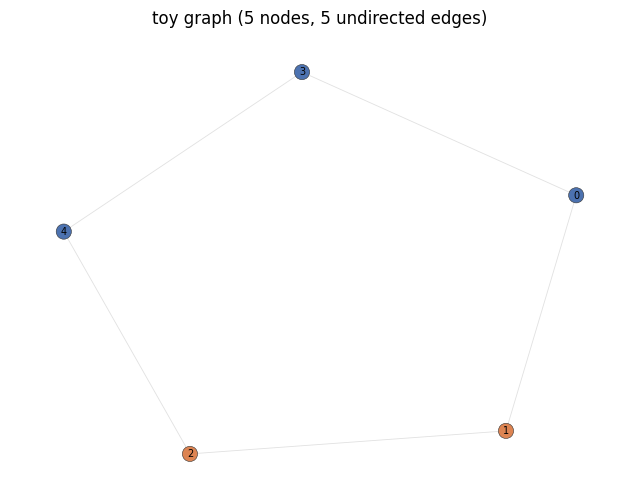

In [41]:
g = toy_graph()
x, edge_index = g["x"], g["edge_index"]

print("features x       :", tuple(x.shape))
print("edge_index       :", tuple(edge_index.shape))
print("  sources (row 0):", edge_index[0].tolist())
print("  targets (row 1):", edge_index[1].tolist())
print()
print("The graph is:")
print("    0 -- 1 -- 2")
print("    |         |")
print("    3 ------- 4")
print()
print("features per node:")
for i, row in enumerate(x.tolist()):
    print(f"  node {i}: {row}")

deg = degree(edge_index[1], num_nodes=5)
print("\ndegree of every node:", deg.tolist(), "-> 2-regular, which is what makes")
print("the hand-computed expected values in section 2 exact rather than approximate.")

draw_graph(edge_index, labels=g["y"], title="toy graph (5 nodes, 5 undirected edges)",
           path=f"{RESULTS}/01_toy_graph.png")

---
# 2. Message passing, done by hand

A graph convolution is an **unsorted group-by**. For every node, gather the
messages arriving from its neighbours and combine them. PyTorch spells that as
`index_add_`. Here is a full GCN layer with no classes, no libraries and no
abstraction -- five lines:

In [42]:
num_nodes = x.size(0)

# --- step 0: the GCN normalisation coefficients -------------------------
# add self-loops, then scale each edge by 1/sqrt(deg_dst * deg_src)
ei, norm = gcn_norm(edge_index, num_nodes)
print("edges after adding self-loops:", ei.size(1), "(10 original + 5 loops)")
print("norm coefficients (unique)   :", sorted({round(float(v), 6) for v in norm}))
print("  -> all 1/3, because every node has degree 3 once the loop is added")

# --- step 1: a linear map, identical to a dense layer -------------------
W = torch.eye(2, dtype=torch.float64)          # identity, so we can read the result
h = x.to(torch.float64) @ W

# --- step 2: MESSAGE. gather from the SOURCE, scale ---------------------
src, dst = ei[0], ei[1]
msg = h.index_select(0, src) * norm.unsqueeze(-1)
print("\nmessage tensor shape:", tuple(msg.shape), "-- one row per directed edge")

# --- step 3: AGGREGATE. scatter onto the DESTINATION --------------------
out = scatter_add(msg, dst, num_nodes)

print("\nhand-written GCN output (W = identity, no bias):")
for i, row in enumerate(out.tolist()):
    print(f"  node {i}: [{row[0]:.4f}, {row[1]:.4f}]")

expected = torch.tensor([[3, 1], [2, 2], [1, 4], [3, 2], [3, 3]], dtype=torch.float64) / 3.0
print("\nmatches the value computed on paper:",
      bool(torch.allclose(out, expected, atol=1e-9)))
print("expected node 0 = (x0 + x1 + x3)/3 = ([1,0]+[0,1]+[2,0])/3 = [1.0000, 0.3333]")

edges after adding self-loops: 15 (10 original + 5 loops)
norm coefficients (unique)   : [0.333333]
  -> all 1/3, because every node has degree 3 once the loop is added

message tensor shape: (15, 2) -- one row per directed edge

hand-written GCN output (W = identity, no bias):
  node 0: [1.0000, 0.3333]
  node 1: [0.6667, 0.6667]
  node 2: [0.3333, 1.3333]
  node 3: [1.0000, 0.6667]
  node 4: [1.0000, 1.0000]

matches the value computed on paper: True
expected node 0 = (x0 + x1 + x3)/3 = ([1,0]+[0,1]+[2,0])/3 = [1.0000, 0.3333]


That is the entire mechanism. Everything else in this notebook is a variation
on those three lines:

| model | message `f` | aggregation | update |
|---|---|---|---|
| **GCN** | `W h_j`, scaled by `1/sqrt(d_i d_j)` | sum | add bias |
| **GraphSAGE** | `h_j` (unchanged) | mean / max / sum | `W_self h_i + W_neigh agg` |
| **GAT** | `W h_j`, scaled by learned `alpha_ij` | sum | add bias |
| **GIN** | `h_j` | sum | `MLP((1+eps) h_i + agg)` |

Now let the library version do it and check it agrees:

In [43]:
conv = GCNConvScratch(2, 2).double().eval()
with torch.no_grad():
    conv.lin.weight.copy_(torch.eye(2, dtype=torch.float64))
    conv.bias.zero_()
    out_layer = conv(x.to(torch.float64), edge_index, num_nodes)

print("GCNConvScratch output matches the five lines above:",
      bool(torch.allclose(out_layer, out, atol=1e-12)))

# and the other three aggregators, on the same graph
for aggr in ("mean", "sum", "max"):
    s = SAGEConvScratch(2, 2, aggr=aggr).double().eval()
    with torch.no_grad():
        s.lin_l.weight.copy_(torch.eye(2, dtype=torch.float64)); s.lin_l.bias.zero_()
        s.lin_r.weight.zero_()
        o = s(x.to(torch.float64), edge_index, num_nodes)
    print(f"\nSAGE aggr={aggr:4} -> node 0 aggregates its neighbours (x1=[0,1], x3=[2,0]) as "
          f"{[round(v, 4) for v in o[0].tolist()]}")

GCNConvScratch output matches the five lines above: True

SAGE aggr=mean -> node 0 aggregates its neighbours (x1=[0,1], x3=[2,0]) as [1.0, 0.5]

SAGE aggr=sum  -> node 0 aggregates its neighbours (x1=[0,1], x3=[2,0]) as [2.0, 1.0]

SAGE aggr=max  -> node 0 aggregates its neighbours (x1=[0,1], x3=[2,0]) as [2.0, 1.0]


In [44]:
# The scatter primitives themselves, checked against a brute-force Python loop.
for r in check_scatter_vs_loop():
    print(r.line())

[PASS] scatter_add  vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_mean vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_max  vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_softmax vs per-group torch.softmax   max|diff|=1.388e-17  tol=1e-12    shapes (40, 3) vs (40, 3)
[PASS] scatter_softmax rows sum to 1 per node       max|diff|=2.220e-16  tol=1e-10    11/11 non-empty groups
[PASS] gradients flow through all scatter ops       max|diff|=-          tol=-        weighted sum().backward() produced finite non-zero grads


---
# 3. Cora

2708 machine-learning papers, 1433 bag-of-words features, 7 classes, 5278
undirected citation edges. The task is **semi-supervised node classification**:
only 140 labelled nodes (20 per class) are used for training, 500 for
validation, 1000 for testing. The other nodes are never labelled, but they are
still *in the graph*, so their structure informs every prediction. That is the
idea that makes GNNs interesting rather than merely different.

Two things about the raw files are worth knowing, both discovered by inspecting
the bytes rather than trusting a README:

1. **`test.index` is not sorted.** Row `k` of the test feature block belongs to
   node `sorted(test_index)[k]`, so concatenating the blocks puts the test rows
   in the wrong order and you must un-permute them.
2. **The adjacency dict contains 302 duplicate entries** -- 10858 entries for a
   graph with 10556 unique directed edges. PyTorch Geometric removes them; the
   original tkipf/gcn code does not. PyG even carries a source comment about it.
   We default to PyG's behaviour so the comparison in section 5 is fair, and
   section 6 measures what the difference is actually worth.

In [45]:
cora = load_cora(source="planetoid", row_normalize=False)   # PyG does not row-normalise
cora = cora.to(DEVICE)
print()
print("on device:", DEVICE)

Cora (planetoid)
  nodes          : 2708
  features       : 1433 (density 0.0127)
  directed edges : 10556 (5278 undirected)
  classes        : 7
  degree         : min 1 / mean 3.90 / max 168
  train/val/test : 140 / 500 / 1000
  note           : deduped 10858 -> 10556 directed edges

on device: cuda


/tmp/ipykernel_50/2161415015.py:128: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  return pickle.load(fh, encoding="latin1")


In [46]:
# The same graph, read from the human-readable LINQS text release instead.
# No scipy involved: one line per paper, one line per citation.
cora_text = load_cora(source="linqs", row_normalize=False)
print()
print("Same graph, different node ordering and a reconstructed split:")
print("  planetoid edges :", cora.num_edges)
print("  linqs edges     :", cora_text.num_edges)
print("  class sizes match:",
      torch.equal(torch.bincount(cora.y.cpu(), minlength=7).sort().values,
                  torch.bincount(cora_text.y.cpu(), minlength=7).sort().values))
# `cora` was moved to the GPU above; `cora_text` was just loaded and is still on the CPU.
# torch.equal refuses to compare tensors on different devices, hence the .cpu() calls.

Cora (linqs)
  nodes          : 2708
  features       : 1433 (density 0.0127)
  directed edges : 10556 (5278 undirected)
  classes        : 7
  degree         : min 1 / mean 3.90 / max 168
  train/val/test : 140 / 500 / 1000
  class names    : Case_Based, Genetic_Algorithms, Neural_Networks, Probabilistic_Methods, Reinforcement_Learning, Rule_Learning, Theory
  note           : cora.cites had 5429 lines -> 5278 unique undirected edges
  note           : public split (seed 42): same protocol as Planetoid

Same graph, different node ordering and a reconstructed split:
  planetoid edges : 10556
  linqs edges     : 10556
  class sizes match: True


  saved results/03_cora.png


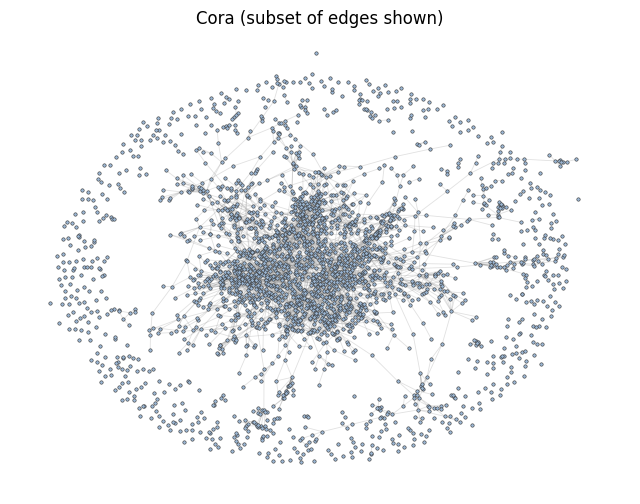

In [47]:
draw_graph(cora.edge_index[:, :4000].cpu(), labels=None, node_size=6,
           title="Cora (subset of edges shown)", path=f"{RESULTS}/03_cora.png")

---
# 4. Train the three canonical architectures

Same protocol for all three, so the comparison means something: 2 hidden layers,
Adam, lr 0.01, weight decay 5e-4, dropout, 200 epochs, full-batch.

**Reporting note.** We report the test accuracy *at the epoch where validation
accuracy peaked*, not the best test accuracy ever seen. Taking the max over
epochs is test-set selection and inflates the number by a point or two -- it is
common in GNN papers and it is wrong. Both numbers are printed so you can see
the gap.


=== GCN ===
    GCN          seed=0  val=79.40%  test=80.00%  (max_test=81.90%)  f1=79.16%  2.3s
    GCN          seed=1  val=78.60%  test=80.90%  (max_test=81.30%)  f1=79.84%  1.2s
    GCN          seed=2  val=78.60%  test=79.90%  (max_test=81.00%)  f1=79.14%  1.2s
  parameters : 23,063
  test acc   : 80.27 +/- 0.45%
  macro F1   : 79.38 +/- 0.32%
  majority   : 31.90%  <- the number to beat

=== SAGE ===
    SAGE         seed=0  val=79.00%  test=79.20%  (max_test=80.90%)  f1=78.77%  1.4s
    SAGE         seed=1  val=77.00%  test=79.40%  (max_test=81.20%)  f1=78.41%  1.4s
    SAGE         seed=2  val=76.80%  test=79.00%  (max_test=79.80%)  f1=77.88%  1.4s
  parameters : 46,103
  test acc   : 79.20 +/- 0.16%
  macro F1   : 78.35 +/- 0.36%
  majority   : 31.90%  <- the number to beat

=== GAT ===
    GAT          seed=0  val=78.80%  test=81.60%  (max_test=81.60%)  f1=80.93%  1.7s
    GAT          seed=1  val=80.40%  test=80.00%  (max_test=81.20%)  f1=79.41%  1.6s
    GAT          seed=

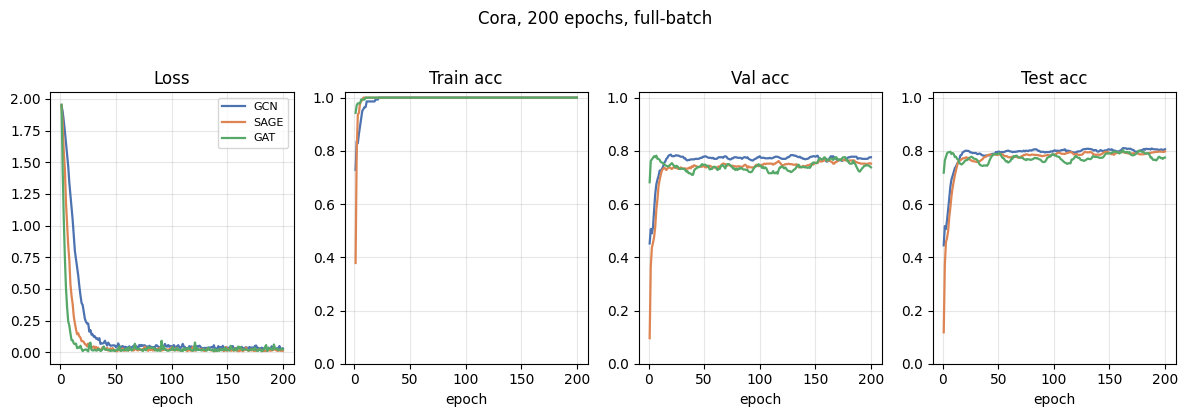

In [48]:
from collections import OrderedDict

def build(name):
    f, h, c = cora.num_features, 16, cora.num_classes
    if name == "gcn":
        return lambda: GCNScratch(f, h, c, num_layers=2, dropout=0.5)
    if name == "sage":
        return lambda: GraphSAGEScratch(f, h, c, num_layers=2, dropout=0.5, aggr="mean")
    if name == "gat":
        return lambda: GATScratch(f, h, c, heads=8, dropout=0.6)
    raise KeyError(name)

SEEDS = [0, 1, 2]
summary = OrderedDict()
histories = {}

for name in ("gcn", "sage", "gat"):
    print(f"\n=== {name.upper()} ===")
    res = train_node_multi_seed(build(name), cora, model_name=name.upper(),
                                seeds=SEEDS, epochs=200, lr=1e-2,
                                weight_decay=5e-4, device=DEVICE)
    summary[name] = res
    histories[name.upper()] = res["results"][-1].history
    print(f"  parameters : {count_parameters(build(name)()):,}")
    print(f"  test acc   : {res['test_acc_mean'] * 100:.2f} +/- {res['test_acc_std'] * 100:.2f}%")
    print(f"  macro F1   : {res['test_f1_mean'] * 100:.2f} +/- {res['test_f1_std'] * 100:.2f}%")
    print(f"  majority   : {res['baseline'] * 100:.2f}%  <- the number to beat")

plot_training_curves(histories, title="Cora, 200 epochs, full-batch",
                     path=f"{RESULTS}/04_training_curves.png")

In [49]:
rows = [{"model": v["model"], "test_acc_mean": v["test_acc_mean"],
         "test_acc_std": v["test_acc_std"]} for v in summary.values()]
plot_results_bars(rows, title="Cora test accuracy (mean over 3 seeds)",
                  baseline=next(iter(summary.values()))["baseline"],
                  path=f"{RESULTS}/04_results.png")

print(f"{'model':8} {'test acc':>18} {'macro F1':>18}")
for v in summary.values():
    print(f"{v['model']:8} {v['test_acc_mean']*100:6.2f} +/- {v['test_acc_std']*100:4.2f}%"
          f"     {v['test_f1_mean']*100:6.2f} +/- {v['test_f1_std']*100:4.2f}%")

  saved results/04_results.png
model              test acc           macro F1
GCN       80.27 +/- 0.45%      79.38 +/- 0.32%
SAGE      79.20 +/- 0.16%      78.35 +/- 0.36%
GAT       80.43 +/- 0.83%      79.88 +/- 0.75%


---
# 5. Is the from-scratch code actually correct?

Writing a GNN from scratch is easy. Writing one that is *right* is not, because
the failure mode is silent. So: build the same layer in PyTorch Geometric, copy
the weights across verbatim, and assert the outputs agree.

This works at all because `gnn_lab` names its parameters the way PyG does --
`lin`/`bias` for GCN, `lin_l`/`lin_r` for SAGE, `lin`/`att_src`/`att_dst` for
GAT, `nn`/`eps` for GIN. That is not an aesthetic choice; it is what turns the
check into `pyg.load_state_dict(mine.state_dict())` instead of a brittle key
mapping that breaks on every PyG release.

Checks run in **float64**. In float32 a 1e-5 tolerance would pass even for a
subtly wrong implementation; agreement to ~1e-12 is evidence the two compute the
same expression, not merely similar ones.

In [50]:
eq_results = run_all(root="data", include_data=True, verbose=True)
print()
print("VERDICT:", "all checks passed" if all_passed(eq_results) else "SOMETHING FAILED")

FROM-SCRATCH  vs  TORCH_GEOMETRIC   --   numerical equivalence
PyG available: True (v2.8.1)


Processing...
Done!


[PASS] scatter_add  vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_mean vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_max  vs python loop                  max|diff|=0.000e+00  tol=1e-12    shapes (11, 3) vs (11, 3)
[PASS] scatter_softmax vs per-group torch.softmax   max|diff|=1.388e-17  tol=1e-12    shapes (40, 3) vs (40, 3)
[PASS] scatter_softmax rows sum to 1 per node       max|diff|=2.220e-16  tol=1e-10    11/11 non-empty groups
[PASS] gradients flow through all scatter ops       max|diff|=-          tol=-        weighted sum().backward() produced finite non-zero grads
[PASS] gcn_norm edge_index matches PyG              max|diff|=-          tol=-        354 vs 354 edges
[PASS] gcn_norm coefficients match PyG              max|diff|=0.000e+00  tol=1e-12    shapes (354,) vs (354,)
[PASS] GCNConvScratch == PyG GCNConv                max|diff|=0.000e+00  tol=1e-10    s

---
# 6. Ablations -- where the understanding actually comes from

Four questions, each with a measurable answer:

1. **Does depth hurt?** Stacking layers grows the receptive field, but message
   passing is diffusion, and diffusion drives every node toward the same value.
   That is over-smoothing, and it is the main reason GNNs are shallow.
2. **Does the aggregator matter?** Same SAGE architecture, `mean` vs `max` vs `sum`.
3. **Do self-loops matter?** Turn them off and a node can no longer see itself.
4. **Do those 302 duplicate edges matter?** A data-hygiene question with a real
   answer, because most tutorials silently pick one behaviour or the other.

=== depth sweep: over-smoothing ===
   1 layers  test 74.90%  cosine 0.2370  energy 2.2417e+01
   2 layers  test 80.00%  cosine 0.1902  energy 8.1319e+00
   3 layers  test 81.10%  cosine 0.2430  energy 1.5408e+02
   4 layers  test 75.50%  cosine 0.2181  energy 4.9176e+02
   6 layers  test 68.50%  cosine 0.2951  energy 6.4821e+02
   8 layers  test 31.10%  cosine 0.8595  energy 2.1565e-03
  12 layers  test 31.00%  cosine 0.8436  energy 5.7530e-04
  saved results/06_oversmoothing.png


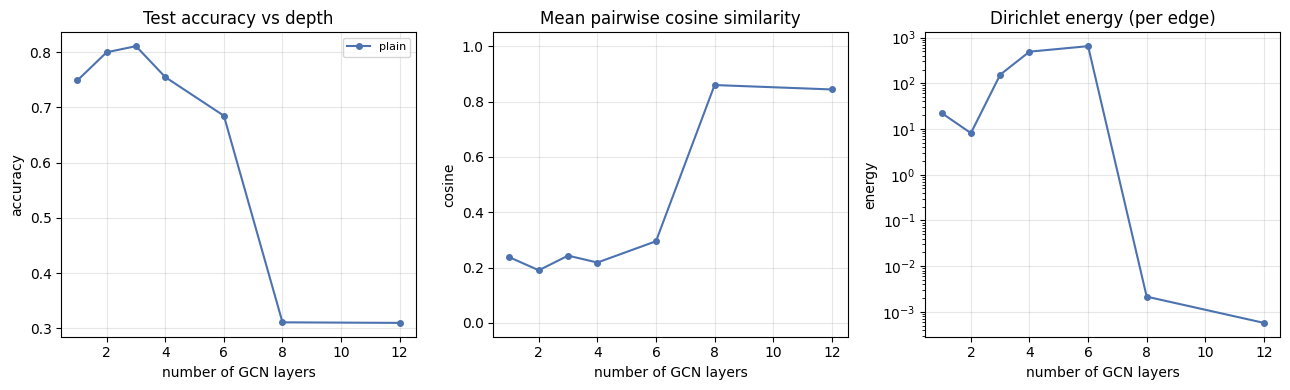

In [51]:
print("=== depth sweep: over-smoothing ===")
depth_rows = []
for depth in (1, 2, 3, 4, 6, 8, 12):
    set_seed(0)
    model = GCNScratch(cora.num_features, 16, cora.num_classes,
                       num_layers=depth, dropout=0.5)
    r = train_node(model, cora, model_name=f"GCN-{depth}L", epochs=200, device=DEVICE)
    with torch.no_grad():
        model.eval()
        h = model.embeddings(cora.x, cora.edge_index)
    depth_rows.append({"depth": depth, "variant": "plain",
                       "test_acc": r.test_acc_at_best_val,
                       "cosine": mean_pairwise_cosine(h),
                       "energy": dirichlet_energy(h, cora.edge_index, cora.num_nodes)})
    print(f"  {depth:2d} layers  test {r.test_acc_at_best_val*100:5.2f}%  "
          f"cosine {depth_rows[-1]['cosine']:.4f}  energy {depth_rows[-1]['energy']:.4e}")

plot_oversmoothing([d["depth"] for d in depth_rows], depth_rows,
                   path=f"{RESULTS}/06_oversmoothing.png")

=== aggregator sweep (GraphSAGE, 2 layers) ===
  aggr=mean   test 79.20%
  aggr=max    test 76.70%
  aggr=sum    test 73.50%

=== self-loop ablation (GCN, 2 layers) ===
  add_self_loops=True   test 80.00%
  add_self_loops=False  test 79.90%
  saved results/06_ablations.png


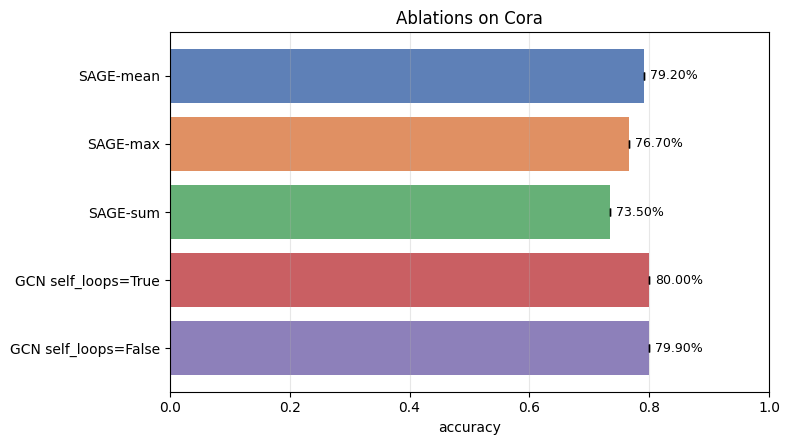

In [52]:
print("=== aggregator sweep (GraphSAGE, 2 layers) ===")
agg_rows = []
for aggr in ("mean", "max", "sum"):
    set_seed(0)
    model = GraphSAGEScratch(cora.num_features, 16, cora.num_classes,
                             num_layers=2, dropout=0.5, aggr=aggr)
    r = train_node(model, cora, model_name=f"SAGE-{aggr}", epochs=200, device=DEVICE)
    agg_rows.append({"model": f"SAGE-{aggr}", "test_acc_mean": r.test_acc_at_best_val,
                     "test_acc_std": 0.0})
    print(f"  aggr={aggr:5}  test {r.test_acc_at_best_val*100:5.2f}%")

print("\n=== self-loop ablation (GCN, 2 layers) ===")
for loops in (True, False):
    set_seed(0)
    model = GCNScratch(cora.num_features, 16, cora.num_classes, num_layers=2,
                       dropout=0.5, add_self_loops=loops)
    r = train_node(model, cora, model_name="GCN", epochs=200, device=DEVICE)
    agg_rows.append({"model": f"GCN self_loops={loops}", "test_acc_mean": r.test_acc_at_best_val,
                     "test_acc_std": 0.0})
    print(f"  add_self_loops={loops!s:5}  test {r.test_acc_at_best_val*100:5.2f}%")

plot_results_bars(agg_rows, title="Ablations on Cora",
                  path=f"{RESULTS}/06_ablations.png")

In [53]:
print("=== duplicate-edge ablation ===")
cora_dup = load_cora(source="planetoid", row_normalize=False, dedupe=False).to(DEVICE)
print("  edges deduped :", cora.num_edges)
print("  edges kept    :", cora_dup.num_edges, f"(+{cora_dup.num_edges - cora.num_edges})")

for label, data in (("deduped (PyG behaviour)", cora), ("with duplicates (tkipf behaviour)", cora_dup)):
    set_seed(0)
    r = train_node(GCNScratch(data.num_features, 16, data.num_classes, num_layers=2,
                              dropout=0.5), data, model_name="GCN", epochs=200, device=DEVICE)
    print(f"  {label:38} test {r.test_acc_at_best_val*100:5.2f}%")

=== duplicate-edge ablation ===
Cora (planetoid)
  nodes          : 2708
  features       : 1433 (density 0.0127)
  directed edges : 10858 (5429 undirected)
  classes        : 7
  degree         : min 1 / mean 4.01 / max 169
  train/val/test : 140 / 500 / 1000
  note           : kept all 10858 adjacency entries (tkipf/gcn behaviour)
  edges deduped : 10556
  edges kept    : 10858 (+302)
  deduped (PyG behaviour)                test 80.00%
  with duplicates (tkipf behaviour)      test 79.80%


### 6b. What does over-smoothing look like?

The accuracy curve above says *that* it happens. The t-SNE plots say *what*
happens: class clusters that are cleanly separated after one layer blur into a
single blob as layers stack.

  saved results/06b_layerwise.png
  saved results/06b_tsne.png


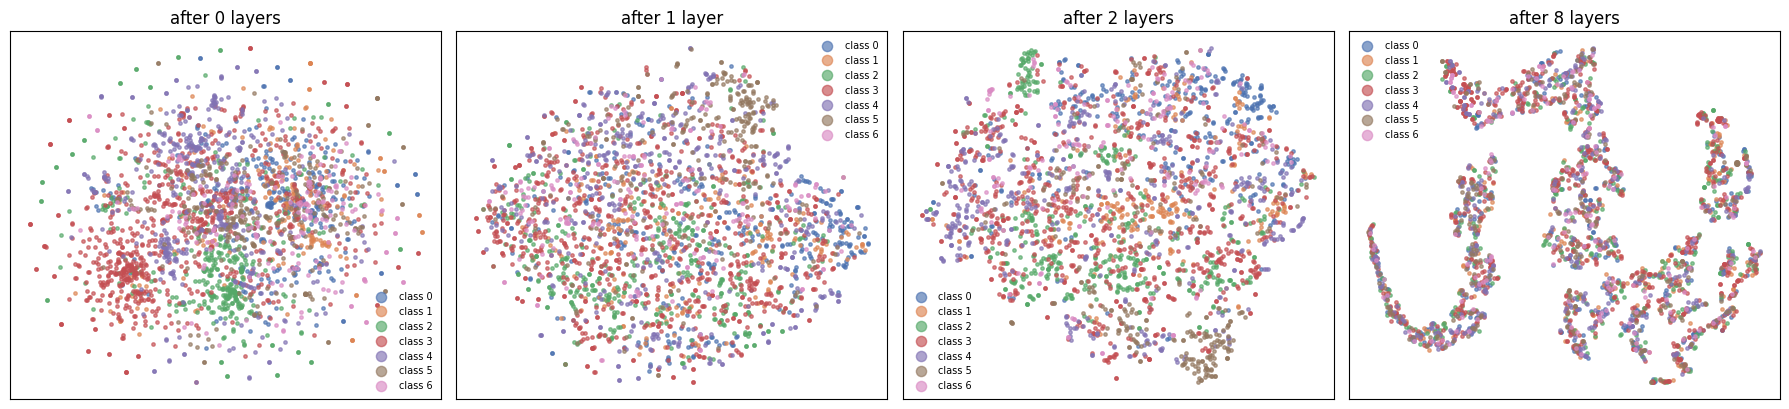

In [54]:
set_seed(0)
deep = GCNScratch(cora.num_features, 16, cora.num_classes, num_layers=8, dropout=0.0).to(DEVICE)
train_node(deep, cora, model_name="GCN-8L", epochs=200, device=DEVICE, log_every=0)

deep.eval()
hs = [cora.x]
with torch.no_grad():
    h = cora.x
    for i, conv in enumerate(deep.convs):
        h = conv(h, cora.edge_index)
        if i < len(deep.convs) - 1:
            h = torch.nn.functional.relu(h)
        hs.append(h)

plot_layerwise_similarity(hs, cora.edge_index,
                          path=f"{RESULTS}/06b_layerwise.png")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, k in zip(axes, (0, 1, 2, 8)):
    if k < len(hs):
        plot_tsne(hs[k], cora.y, title=f"after {k} layer" + ("" if k == 1 else "s"),
                  ax=ax, seed=0)
fig.tight_layout()
save_or_show(fig, f"{RESULTS}/06b_tsne.png")

---
# 7. What is GAT's attention actually doing?

The claim is that GAT learns to weight informative neighbours more heavily. That
is falsifiable: split the learned attention coefficients into edges that connect
two nodes of the *same* class and edges that connect *different* classes, and
compare the distributions. If attention is doing its job, the same-class
distribution sits to the right.

On homophilous Cora the separation is visible but far from clean. That is the
honest result, and it is a useful corrective to figures that make attention
look like a perfect edge classifier.

edges with attention: 13264
  same-class  edges: 11258  mean attention 0.2095
  cross-class edges:  2006  mean attention 0.1744
  ratio same/cross : 1.201
  saved results/07_attention.png


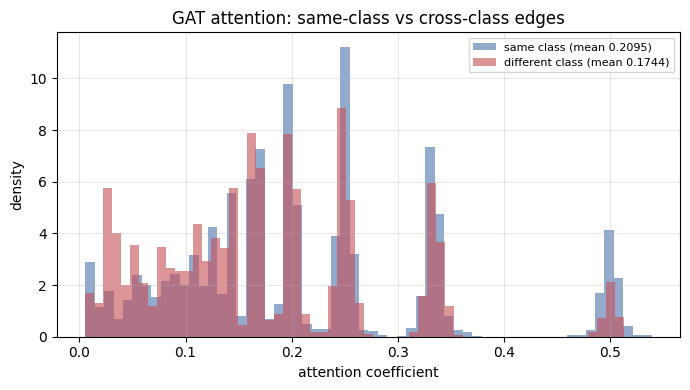

In [55]:
set_seed(0)
gat = GATScratch(cora.num_features, 8, cora.num_classes, heads=8, dropout=0.0).to(DEVICE)
train_node(gat, cora, model_name="GAT", epochs=200, device=DEVICE)

ei_att, att = gat.attention_weights(cora.x, cora.edge_index, layer=0)
att = att.detach().cpu()
src_i, dst_i = ei_att[0].cpu(), ei_att[1].cpu()
y_cpu = cora.y.cpu()
same = y_cpu[src_i] == y_cpu[dst_i]

per_edge = att.mean(dim=1)          # average across the 8 heads
print("edges with attention:", per_edge.numel())
print(f"  same-class  edges: {int(same.sum()):5d}  mean attention {per_edge[same].mean():.4f}")
print(f"  cross-class edges: {int((~same).sum()):5d}  mean attention {per_edge[~same].mean():.4f}")
print(f"  ratio same/cross : {per_edge[same].mean() / per_edge[~same].mean():.3f}")

plot_attention_distribution(per_edge[same], per_edge[~same],
                            path=f"{RESULTS}/07_attention.png")

attention mean per head, same-class vs cross-class edges:
 head      same     cross    ratio
    0    0.2095    0.1745    1.201
    1    0.2094    0.1750    1.197
    2    0.2094    0.1750    1.197
    3    0.2095    0.1742    1.203
    4    0.2094    0.1747    1.199
    5    0.2095    0.1742    1.202
    6    0.2096    0.1734    1.209
    7    0.2094    0.1747    1.199
  saved results/07_attention_graph.png


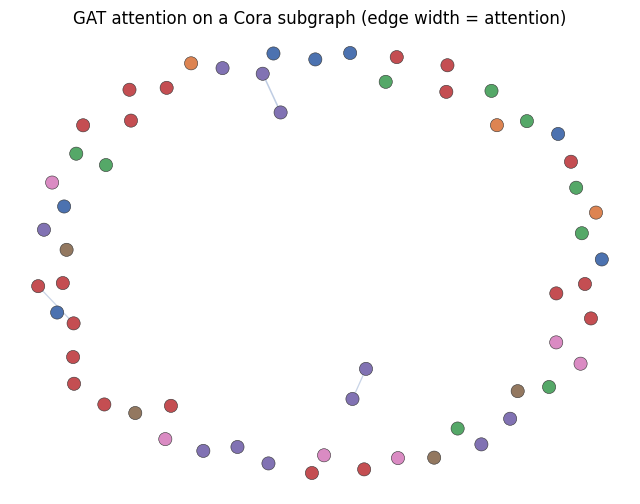

In [56]:
# Per-head behaviour: do the 8 heads specialise, or do they all agree?
print("attention mean per head, same-class vs cross-class edges:")
print(f"{'head':>5} {'same':>9} {'cross':>9} {'ratio':>8}")
for hnd in range(att.size(1)):
    s = float(att[same, hnd].mean()); d = float(att[~same, hnd].mean())
    print(f"{hnd:>5} {s:>9.4f} {d:>9.4f} {s / max(d, 1e-12):>8.3f}")

# draw a subgraph with edge width proportional to attention
sub = torch.arange(60)
mask = torch.isin(src_i, sub) & torch.isin(dst_i, sub)
draw_graph(ei_att[:, mask], labels=y_cpu[sub],
           highlight_edges=per_edge[mask].float(),
           title="GAT attention on a Cora subgraph (edge width = attention)",
           path=f"{RESULTS}/07_attention_graph.png", node_size=90)

---
# 8. Graph-level classification: GIN on MUTAG

Everything so far predicted a label per *node* in one fixed graph. Now the task
flips: 188 small molecules, each with a single label (mutagenic or not), and the
model must learn a function from whole-graph structure to that class.

Two new ingredients appear:

* **Batching.** Molecules have 10-28 atoms, so they cannot be stacked into a 4-D
  tensor. Instead they are concatenated into one block-diagonal graph plus a
  `batch` vector saying which molecule each node belongs to. No information can
  leak between molecules because they are physically disconnected.
* **Readout.** Node embeddings must collapse into one vector per molecule. Sum,
  mean or max -- and the choice changes what the model can see.

MUTAG is **imbalanced**: 63 vs 125. The majority-class baseline is **66.5%, not
50%**. Any number below that is worse than a constant.

In [57]:
mutag = load_mutag()
print()
print("first molecule:", mutag.graphs[0]["x"].shape[0], "atoms,",
      mutag.graphs[0]["edge_index"].shape[1], "directed bonds, label",
      int(mutag.graphs[0]["y"]))

  downloading https://www.chrsmrrs.com/graphkerneldatasets/MUTAG.zip
MUTAG
  graphs            : 188
  total nodes       : 3371
  total dir. edges  : 7442
  node features     : 7
  nodes/graph       : min 10 / mean 17.93 / max 28
  classes           : 2 [63, 125]
  majority baseline : 0.665
  note              : 188 mutagenic aromatic/nitro compounds; predict mutagenicity

first molecule: 17 atoms, 38 directed bonds, label 1


In [58]:
# Show the batching trick explicitly: two graphs -> one block-diagonal graph.
b = collate_graphs(mutag.graphs[:3])
print(b)
print("batch vector:", b.batch.tolist())
print("edge_index (note the offsets that keep graphs disconnected):")
print(b.edge_index.t().tolist()[:12], "...")

# Proof that batching cannot leak information between graphs.
conv = GINConvScratch(torch.nn.Sequential(torch.nn.Linear(mutag.num_features, 8),
                                          torch.nn.ReLU(),
                                          torch.nn.Linear(8, 8))).double().eval()
with torch.no_grad():
    joint = conv(b.x.double(), b.edge_index, b.num_nodes)
    ok = True
    node_ptr = 0
    for k, gr in enumerate(mutag.graphs[:3]):
        alone = conv(gr["x"].double(), gr["edge_index"], gr["x"].size(0))
        n = gr["x"].size(0)
        ok &= bool(torch.allclose(joint[node_ptr:node_ptr + n], alone, atol=1e-12))
        node_ptr += n
print("\nbatched forward == per-graph forward for every graph:", ok)

BatchedGraph(graphs=3, nodes=43, edges=94, x=(43, 7))
batch vector: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
edge_index (note the offsets that keep graphs disconnected):
[[1, 0], [0, 1], [2, 1], [1, 2], [3, 2], [2, 3], [4, 3], [3, 4], [5, 4], [4, 5], [5, 0], [0, 5]] ...

batched forward == per-graph forward for every graph: True


=== GIN on MUTAG, 5-fold cross-validation ===
  fold 1/5  val  86.7%  test  86.8%  f1  84.4%
  fold 2/5  val 100.0%  test  71.1%  f1  71.0%
  fold 3/5  val  93.3%  test  63.2%  f1  60.4%
  fold 4/5  val  86.7%  test  91.9%  f1  90.9%
  fold 5/5  val 100.0%  test  67.6%  f1  40.3%
  => GIN-sum: acc 76.10 +/- 11.23%  (majority baseline 66.5%)
  fold 1/5  val  93.3%  test  86.8%  f1  85.1%
  fold 2/5  val  93.3%  test  73.7%  f1  73.4%
  fold 3/5  val 100.0%  test  71.1%  f1  63.8%
  fold 4/5  val  86.7%  test  70.3%  f1  58.0%
  fold 5/5  val 100.0%  test  67.6%  f1  40.3%
  => GIN-mean: acc 73.88 +/- 6.77%  (majority baseline 66.5%)
  fold 1/5  val  86.7%  test  86.8%  f1  84.4%
  fold 2/5  val  86.7%  test  68.4%  f1  68.1%
  fold 3/5  val  93.3%  test  55.3%  f1  49.3%
  fold 4/5  val  86.7%  test  75.7%  f1  68.1%
  fold 5/5  val 100.0%  test  67.6%  f1  40.3%
  => GIN-max: acc 70.75 +/- 10.38%  (majority baseline 66.5%)
  saved results/08_mutag.png


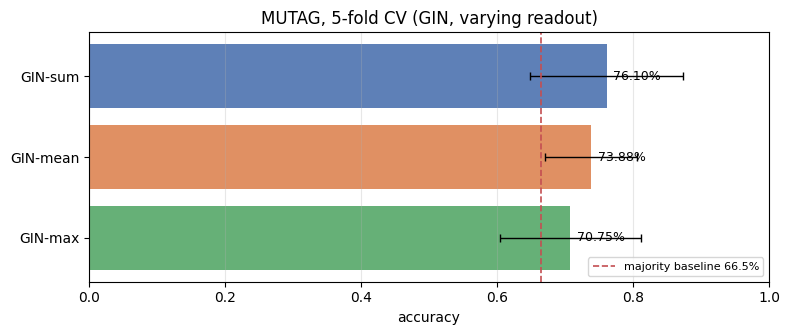

In [59]:
print("=== GIN on MUTAG, 5-fold cross-validation ===")
def build_gin(pool="sum"):
    return lambda: GINScratch(mutag.num_features, 32, mutag.num_classes,
                              num_layers=3, dropout=0.5, pool=pool)

mutag_results = []
for pool in ("sum", "mean", "max"):
    r = train_graph_classification(build_gin(pool), mutag, model_name=f"GIN-{pool}",
                                   epochs=80, batch_size=32, folds=5, device=DEVICE)
    mutag_results.append({"model": r["model"], "test_acc_mean": r["acc_mean"],
                          "test_acc_std": r["acc_std"]})

plot_results_bars(mutag_results, title="MUTAG, 5-fold CV (GIN, varying readout)",
                  baseline=mutag.majority_accuracy(),
                  path=f"{RESULTS}/08_mutag.png")

### 8b. The expressiveness argument, made concrete

The GIN paper proves that mean and max aggregation cannot distinguish certain
non-isomorphic graphs -- they cannot *count*. Concretely: a node with one
neighbour of feature 1 and a node with two neighbours of feature 0.5 have the
same mean and the same max, but different structure.

A theorem can feel abstract, so here is a dataset built around it, and an honest
caveat. `triangle_vs_square` makes graphs whose label is "does this graph contain
a triangle?". Classes are built in matched pairs (same node and edge counts; the
positive graph is the negative one with one edge moved), so size and density are
not shortcuts. An earlier version without that matching let edge density predict
the label at 88%, and `sum` appeared to win -- a leak, not expressiveness.

Expected outcome: **every readout near 50%.** The theorem is about the aggregator
inside each layer, this model always sums there, and triangle detection is beyond
1-WL message passing anyway. A clearly positive gap here would mean a shortcut
crept back in.


majority baseline: 0.5 (balanced by construction)
  fold 1/3  val  53.8%  test  50.0%  f1  47.5%
  fold 2/3  val  65.4%  test  52.2%  f1  51.5%
  fold 3/3  val  57.7%  test  48.5%  f1  48.1%
  => GIN-mean-pool: acc 50.24 +/- 1.54%  (majority baseline 50.0%)
  fold 1/3  val  65.4%  test  45.5%  f1  44.8%
  fold 2/3  val  42.3%  test  46.3%  f1  45.7%
  fold 3/3  val  53.8%  test  51.5%  f1  42.6%
  => GIN-sum-pool: acc 47.77 +/- 2.67%  (majority baseline 50.0%)
  saved results/08b_triangle.png


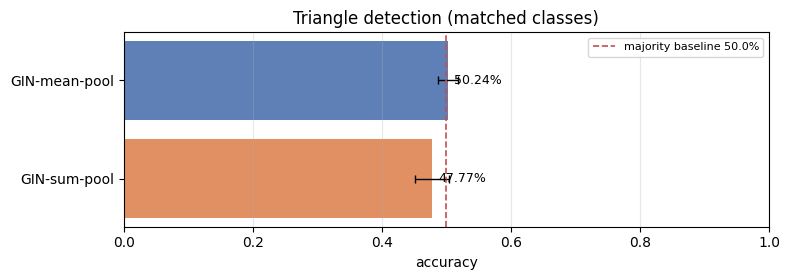

In [60]:
ts = triangle_square_dataset(num_graphs=400, seed=0)
print()
print("majority baseline:", round(ts.majority_accuracy(), 3), "(balanced by construction)")

ts_results = []
for pool in ("mean", "sum"):
    def build(pool=pool):
        return lambda: GINScratch(ts.num_features, 32, ts.num_classes,
                                  num_layers=3, dropout=0.5, pool=pool)
    r = train_graph_classification(build(), ts, model_name=f"GIN-{pool}-pool",
                                   epochs=60, batch_size=32, folds=3, device=DEVICE)
    ts_results.append({"model": r["model"], "test_acc_mean": r["acc_mean"],
                       "test_acc_std": r["acc_std"]})

plot_results_bars(ts_results, title="Triangle detection (matched classes)",
                  baseline=0.5, path=f"{RESULTS}/08b_triangle.png")

---
# 9. What this run showed

**Mechanics.** A graph convolution is `gather from src` + `scatter onto dst` +
`update`. Section 2 wrote one in five lines and matched a value computed on
paper. GCN, GraphSAGE, GAT and GIN differ only in the message function, the
aggregation operator, and the update rule.

**Correctness.** Section 5 compared every hand-written layer against PyTorch
Geometric in float64 with weights copied across verbatim. That is the only check
that catches the silent bugs -- swapping `src` and `dst` produces a model that
trains happily and answers the wrong question.

**Why GNNs are shallow.** Section 6: accuracy falls off as depth grows while
mean pairwise cosine similarity climbs toward 1 and Dirichlet energy falls
toward 0. Message passing is diffusion; enough of it and every node looks the
same. The t-SNE panels show the clusters merging.

**What attention buys.** Section 7: same-class edges do receive more attention
than cross-class ones, but the distributions overlap heavily. Attention is a
soft, learned reweighting -- not an edge classifier.

**Structure vs features.** Section 8: on a task whose label *is* a substructure
(a triangle), with density shortcuts removed, every readout sits near chance --
the limit of 1-WL message passing, and a reminder that the first version of this
experiment "worked" only because of a leak.

**Data hygiene.** Section 6 also measured the effect of the 302 duplicate
adjacency entries in Cora. Small, but real -- and most tutorials pick a side
without mentioning it.

In [61]:
print("=" * 72)
print("RESULTS SUMMARY")
print("=" * 72)
print("\n-- Cora node classification (mean over %d seeds) --" % len(SEEDS))
print(f"{'model':10} {'test acc':>18} {'macro F1':>18}")
for v in summary.values():
    print(f"{v['model']:10} {v['test_acc_mean']*100:6.2f} +/- {v['test_acc_std']*100:4.2f}%"
          f"     {v['test_f1_mean']*100:6.2f} +/- {v['test_f1_std']*100:4.2f}%")
print(f"{'baseline':10} {next(iter(summary.values()))['baseline']*100:6.2f}% (majority class)")

print("\n-- Cora depth sweep (GCN) --")
for d in depth_rows:
    print(f"  {d['depth']:2d} layers  test {d['test_acc']*100:5.2f}%  "
          f"cosine {d['cosine']:.4f}  energy {d['energy']:.3e}")

print("\n-- MUTAG graph classification (5-fold CV) --")
for r in mutag_results:
    print(f"  {r['model']:12} {r['test_acc_mean']*100:6.2f} +/- {r['test_acc_std']*100:4.2f}%")
print(f"  {'baseline':12} {mutag.majority_accuracy()*100:6.2f}% (majority class)")

print("\n-- Triangle detection (3-fold CV) --")
for r in ts_results:
    print(f"  {r['model']:16} {r['test_acc_mean']*100:6.2f} +/- {r['test_acc_std']*100:4.2f}%")

print("\nequivalence checks:",
      sum(1 for r in eq_results if r.passed is True), "passed /",
      sum(1 for r in eq_results if r.passed is False), "failed /",
      sum(1 for r in eq_results if r.passed is None), "skipped")
print("\nfigures written to:", os.path.abspath(RESULTS))
print(sorted(os.listdir(RESULTS)))

RESULTS SUMMARY

-- Cora node classification (mean over 3 seeds) --
model                test acc           macro F1
GCN         80.27 +/- 0.45%      79.38 +/- 0.32%
SAGE        79.20 +/- 0.16%      78.35 +/- 0.36%
GAT         80.43 +/- 0.83%      79.88 +/- 0.75%
baseline    31.90% (majority class)

-- Cora depth sweep (GCN) --
   1 layers  test 74.90%  cosine 0.2370  energy 2.242e+01
   2 layers  test 80.00%  cosine 0.1902  energy 8.132e+00
   3 layers  test 81.10%  cosine 0.2430  energy 1.541e+02
   4 layers  test 75.50%  cosine 0.2181  energy 4.918e+02
   6 layers  test 68.50%  cosine 0.2951  energy 6.482e+02
   8 layers  test 31.10%  cosine 0.8595  energy 2.156e-03
  12 layers  test 31.00%  cosine 0.8436  energy 5.753e-04

-- MUTAG graph classification (5-fold CV) --
  GIN-sum       76.10 +/- 11.23%
  GIN-mean      73.88 +/- 6.77%
  GIN-max       70.75 +/- 10.38%
  baseline      66.49% (majority class)

-- Triangle detection (3-fold CV) --
  GIN-mean-pool     50.24 +/- 1.54%
  GIN-